In [213]:
"""Побудова відредагованої бази data/mbc_base.csv з таблиць OECD ICIO.

Запуск із папки проєкту: python build_base.py  (або по комірках # %%).
"""


# %% [markdown]
# # 01. Побудова відредагованої бази `mbc_base.csv` з таблиць OECD ICIO
#
# **Вхід:**
# * повні таблиці OECD ICIO 2025 `raw/icio_full/{YEAR}_SML.csv` (81 країна + ROW × 50 галузей) — **основне джерело**; зараз є 2022;
# * для років без повної таблиці — вивантаження `raw/icio/{COUNTRY}-{YEAR}.csv` (IND, SAU, UKR, USA × 2015, 2019, 2021).
#
# Коли з'являться повні таблиці за 2015, 2019, 2021 — достатньо покласти їх у `raw/icio_full/` і перезапустити блокнот.
# **Вихід:** `data/mbc_base.csv` — єдина база для розрахунків; `data/corrections_log.csv` — журнал усіх виправлень; `data/validation_report.csv` — перевірки після виправлень.
#
# Кожне виправлення виконується кодом і записується в журнал, тому результат повністю відтворюваний.


# %%
from pathlib import Path
import numpy as np
import pandas as pd

RAW = Path('raw/icio')
OUT = Path('data'); OUT.mkdir(exist_ok=True)
pd.set_option('display.width', 220, 'display.max_columns', 40)

# Агрегування кодів ICIO у 13 галузей і компоненти рахунку
ICIO_MAP = {
    'B05': 'COAL', 'B06': 'OILGAS', 'B07': 'ORES', 'C19': 'COKE', 'C24A': 'METAL', 'C25': 'FABMET',
    'D': 'ELEC', 'E': 'WASTE', 'F': 'CONSTR', 'G': 'TRADE',
    'H49': 'TRANSP', 'H50': 'TRANSP', 'H51': 'TRANSP', 'H52': 'WAREH', 'OTHERS': 'OTHERS',
    'TOTAL_IC': 'TOTAL_IC',
    'HFCE': 'HH', 'NPISH': 'NPISH', 'GGFC': 'GOV', 'GFCF': 'GFCF', 'INVNT': 'INVNT', 'DPABR': 'DPABR',
    'OUT': 'OUTPUT', 'EXP': 'EXPORT', 'IMP': 'IMPORT',
    'VA': None,   # у джерелі = OUT − TOTAL_IC за рядком, тобто не ВДВ → не переноситься
}
IND = ['COAL', 'OILGAS', 'ORES', 'COKE', 'METAL', 'FABMET', 'ELEC',
       'WASTE', 'CONSTR', 'TRADE', 'TRANSP', 'WAREH', 'OTHERS']
IND12 = IND[:-1]
FD = ['HH', 'NPISH', 'GOV', 'GFCF', 'INVNT', 'DPABR']
COLS = [*IND, 'TOTAL_IC', *FD, 'OUTPUT', 'EXPORT', 'IMPORT']
NAMES = {'COAL': 'Coal mining', 'OILGAS': 'Oil and gas extraction', 'ORES': 'Metal ores mining',
         'COKE': 'Coke and refined petroleum products', 'METAL': 'Basic iron and steel (C24A)',
         'FABMET': 'Fabricated metal products', 'ELEC': 'Electricity, gas and steam',
         'WASTE': 'Water supply and waste management', 'CONSTR': 'Construction',
         'TRADE': 'Wholesale and retail trade', 'TRANSP': 'Transport (H49+H50+H51)',
         'WAREH': 'Warehousing and support activities (H52)', 'OTHERS': 'Other industries and services',
         'TOTAL_IC': 'Total domestic intermediate inputs (column sums)',
         'IMP_IC': 'Imported intermediate inputs', 'TLS': 'Taxes less subsidies on products',
         'VA': 'Gross value added', 'OUTPUT': 'Output (column)'}
log = []   # журнал виправлень: (country, year, what, detail)

def rel(a, e):
    a, e = np.asarray(a, float), np.asarray(e, float)
    m = ~np.isnan(a) & ~np.isnan(e)
    return float(np.max(np.abs(a[m] - e[m]) / np.maximum(np.abs(e[m]), 1))) if m.any() else np.nan


# %% [markdown]
# ## 1. Читання та агрегування
#
# Розбір за кодом ICIO в назві (`UKR_C24A` → країна `UKR`, код `C24A`). Колонки, що належать іншій країні (`IRL_HFCE`, `VNM_HFCE`) або кодам без відповідника (`A01`–`A03` у SAU 2015), не переносяться й записуються в журнал.


# %%
def split_label(lbl, country):
    head, _, tail = str(lbl).partition('_')
    if not tail:                         # 'OUT'
        return country, head.upper()
    return head.upper(), tail.upper()

def read_block(path):
    country, year = path.stem.split('-')
    year = int(year)
    df = pd.read_csv(path, sep=';', decimal=',', encoding='utf-8-sig', index_col=0)
    df = df.apply(pd.to_numeric, errors='coerce')
    cmap, rmap = {}, {}
    for c in df.columns:
        cc, code_ = split_label(c, country)
        if cc != country or code_ not in ICIO_MAP:
            log.append((country, year, 'dropped column', f'{c}: sum = {df[c].sum():.2f}'))
        elif ICIO_MAP[code_]:
            cmap[c] = ICIO_MAP[code_]
    for r in df.index:
        cc, code_ = split_label(r, country)
        if ICIO_MAP.get(code_):
            rmap[r] = ICIO_MAP[code_]
    d = df.loc[list(rmap), list(cmap)]
    d = d.T.groupby(cmap).sum(min_count=1).T.groupby(rmap).sum(min_count=1)
    return country, year, d.reindex(index=[*IND, 'TOTAL_IC'], columns=COLS)

blocks = {}
for p in sorted(RAW.glob('*-*.csv')):
    c, y, d = read_block(p)
    blocks[(c, y)] = d
print(len(blocks), 'блоків:', sorted(blocks))


# %% [markdown]
# ## 2. Виправлення
#
# | Блок | Проблема у джерелі | Виправлення | Статус |
# |---|---|---|---|
# | UKR 2021 | рядок TOTAL_IC менший за суму стовпців рівно на рядок ORES (рядок руд пропущено при підсумовуванні) | TOTAL_IC за стовпцями перераховано як суму 13 рядків | `ok` |
# | IND 2022 | рядок і стовпець OTHERS хибні (OTHERS→METAL 141 714 при 10 836 у 2021; OTHERS×OTHERS < 0) | OTHERS відновлено як залишок: TOTAL_IC − Σ 12 галузей; OTHERS×OTHERS невідомий | `reconstructed` |
# | USA 2022 | рядок OTHERS хибний (OTHERS→COKE 439 237 при 36 371 у 2021); стовпець узгоджений | рядок OTHERS відновлено як залишок; OTHERS×OTHERS невідомий | `reconstructed` |
# | SAU 2022 | рядок і стовпець OTHERS хибні | відновлено як залишок | `unreliable` |
#
# Блоки 2022 року потім **замінюються** даними повної таблиці ICIO (розділ 3); звірка показала, що відновлені залишком значення OTHERS збігаються з ICIO, а помилка вивантаження полягала також у заниженому експорті.
# | SAU 2015 | колонки A01–A03 без рядків, не входять у TOTAL_IC | не переносяться (узгоджено з TOTAL_IC) | `ok` (примітка) |
# | IND 2021, USA 2021 | колонки `IRL_HFCE`, `VNM_HFCE` — кінцевий попит інших країн | не переносяться | `ok` (примітка) |
#
# Залишок рахується лише для перетинів OTHERS з 12 галузями; OTHERS×OTHERS і підсумки для OTHERS лишаються порожніми, бо для них немає незалежного контрольного значення.


# %%
STATUS = {k: 'ok' for k in blocks}
NOTE = {k: [] for k in blocks}
ROW_NOTE = {}

def fix_total_row(c, y):
    d = blocks[(c, y)]
    old = d.loc['TOTAL_IC', IND].copy()
    new = d.loc[IND, IND].sum()
    gap = new - old
    d.loc['TOTAL_IC', IND] = new
    log.append((c, y, 'TOTAL_IC row recomputed', f'max change {gap.abs().max():.2f}; '
                f'gap equals ORES row: {np.allclose(gap, d.loc["ORES", IND], atol=0.01)}'))
    NOTE[(c, y)].append('TOTAL_IC row recomputed as column sums (ORES row omitted in source)')

def reconstruct_others(c, y, row=True, col=True, status='reconstructed'):
    d = blocks[(c, y)]
    if row:
        old = d.loc['OTHERS', IND12].copy()
        d.loc['OTHERS', IND12] = d.loc['TOTAL_IC', IND12] - d.loc[IND12, IND12].sum()
        log.append((c, y, 'OTHERS row reconstructed',
                    f'OTHERS→METAL {old["METAL"]:.0f} → {d.loc["OTHERS", "METAL"]:.0f}'))
        ROW_NOTE[(c, y, 'OTHERS')] = 'row reconstructed as residual (TOTAL_IC − Σ 12 industries)'
    if col:
        old = d.loc[IND12, 'OTHERS'].copy()
        d.loc[IND12, 'OTHERS'] = d.loc[IND12, 'TOTAL_IC'] - d.loc[IND12, IND12].sum(axis=1)
        log.append((c, y, 'OTHERS column reconstructed',
                    f'METAL→OTHERS {old["METAL"]:.0f} → {d.loc["METAL", "OTHERS"]:.0f}'))
    d.loc['OTHERS', 'OTHERS'] = np.nan
    d.loc['OTHERS', 'TOTAL_IC'] = np.nan
    d.loc['TOTAL_IC', ['OTHERS', 'TOTAL_IC']] = np.nan
    neg = [(i, j) for i in IND for j in IND if d.loc[i, j] < 0]
    if neg:
        log.append((c, y, 'negative residuals', str(neg)))
    STATUS[(c, y)] = status
    NOTE[(c, y)].append(f'OTHERS {"row" if row else ""}{" and " if row and col else ""}{"column" if col else ""} '
                        'reconstructed as residual; OTHERS×OTHERS unknown')

fix_total_row('UKR', 2021)
reconstruct_others('IND', 2022, row=True, col=True)
reconstruct_others('USA', 2022, row=True, col=False)
reconstruct_others('SAU', 2022, row=True, col=True, status='unreliable')
NOTE[('SAU', 2022)].append('residual values implausible vs 2021; re-extract from ICIO')

for (c, y, what, detail) in log:
    if what == 'dropped column':
        NOTE[(c, y)].append(f'dropped source column {detail.split(":")[0]}')

print(pd.DataFrame(log, columns=['country', 'year', 'action', 'detail']))


# %% [markdown]
# ## 3. Блоки з повної таблиці ICIO
#
# Для років, за які є повна таблиця, блоки чотирьох країн будуються безпосередньо з неї й **замінюють** вивантаження. Визначення:
#
# | Показник | Обчислення з ICIO |
# |---|---|
# | Z (13×13) | вітчизняні рядки країни × вітчизняні стовпці галузей, агреговані за відповідністю кодів (усі коди поза переліком → OTHERS, зокрема A01–A03, C24B, H53, I…T) |
# | кінцевий попит | вітчизняні рядки × власні стовпці HFCE…DPABR |
# | `EXPORT` | вітчизняні рядки × усі стовпці інших країн (проміжні та кінцеві) |
# | `IMPORT` | іноземні рядки продукту, використані в країні (проміжне + кінцеве), довідково |
# | рядок `IMP_IC` | імпортні проміжні витрати галузі-споживача (іноземні рядки × її стовпець) |
# | рядок `TLS` | податки мінус субсидії на продукти, сплачені галуззю-споживачем |
# | рядок `VA` | валова додана вартість (рядок VA ICIO) |
# | рядок `OUTPUT` | випуск за стовпцем (рядок OUT ICIO) |
#
# Тотожності: `TOTAL_IC + FD + EXPORT = OUTPUT` (за рядком) і `TOTAL_IC + IMP_IC + TLS + VA = OUTPUT` (за стовпцем).


# %%
FULL = Path('raw/icio_full')
COUNTRIES = ['IND', 'SAU', 'UKR', 'USA']
MAP_FULL = {k: v for k, v in ICIO_MAP.items() if v in IND}          # B05…H52; решта → OTHERS
FDMAP = {'HFCE': 'HH', 'NPISH': 'NPISH', 'GGFC': 'GOV', 'GFCF': 'GFCF', 'INVNT': 'INVNT', 'DPABR': 'DPABR'}
EXTRA_ROWS = ['IMP_IC', 'TLS', 'VA', 'OUTPUT']

def sector(code_):
    return MAP_FULL.get(code_, 'OTHERS')

def aggregate_full(df, cc):
    ind_rows = [r for r in df.index if '_' in r]
    ind_set = set(ind_rows)
    dom_rows = [r for r in ind_rows if r.startswith(cc + '_')]
    for_rows = [r for r in ind_rows if not r.startswith(cc + '_')]
    ind_cols = [c for c in df.columns if c in ind_set]
    dom_cols = [c for c in ind_cols if c.startswith(cc + '_')]
    fd_cols = [c for c in df.columns if c not in ind_set and c != 'OUT']
    dom_fd = [c for c in fd_cols if c.startswith(cc + '_')]
    for_use = [c for c in ind_cols + fd_cols if not c.startswith(cc + '_')]

    rmap = {r: sector(r.split('_', 1)[1]) for r in dom_rows}
    cmap = {c: sector(c.split('_', 1)[1]) for c in dom_cols}
    fdmap = {c: FDMAP[c.split('_', 1)[1]] for c in dom_fd}
    pmap = {r: sector(r.split('_', 1)[1]) for r in for_rows}
    by_rows = lambda d, m: d.groupby(m).sum()
    by_cols = lambda d, m: d.T.groupby(m).sum().T

    Z = by_cols(by_rows(df.loc[dom_rows, dom_cols], rmap), cmap).reindex(index=IND, columns=IND)
    blk = pd.DataFrame(index=[*IND, 'TOTAL_IC', *EXTRA_ROWS], columns=COLS, dtype=float)
    blk.loc[IND, IND] = Z.values
    blk.loc[IND, 'TOTAL_IC'] = Z.sum(axis=1).values
    blk.loc['TOTAL_IC', IND] = Z.sum().values
    blk.loc['TOTAL_IC', 'TOTAL_IC'] = Z.values.sum()
    blk.loc[IND, FD] = by_cols(by_rows(df.loc[dom_rows, dom_fd], rmap), fdmap).reindex(index=IND, columns=FD).values
    blk.loc[IND, 'OUTPUT'] = by_rows(df.loc[dom_rows, 'OUT'], rmap).reindex(IND).values
    blk.loc[IND, 'EXPORT'] = by_rows(df.loc[dom_rows, for_use].sum(axis=1), rmap).reindex(IND).values
    blk.loc[IND, 'IMPORT'] = by_rows(df.loc[for_rows, dom_cols + dom_fd].sum(axis=1), pmap).reindex(IND).values
    blk.loc['IMP_IC', IND] = by_cols(df.loc[for_rows, dom_cols].sum().to_frame().T, cmap).iloc[0].reindex(IND).values
    for r_src, r_dst in [('TLS', 'TLS'), ('VA', 'VA'), ('OUT', 'OUTPUT')]:
        blk.loc[r_dst, IND] = by_cols(df.loc[[r_src], dom_cols], cmap).iloc[0].reindex(IND).values
    return blk

# блоки з вивантажень доповнюються порожніми рядками IMP_IC, TLS, VA і рядком OUTPUT (= колонка OUTPUT)
for k, d in blocks.items():
    d = d.reindex(index=[*IND, 'TOTAL_IC', *EXTRA_ROWS])
    d.loc['OUTPUT', IND] = d.loc[IND, 'OUTPUT'].values
    blocks[k] = d

for path in sorted(FULL.glob('*_SML.csv')):
    year = int(path.stem.split('_')[0])
    full = pd.read_csv(path, index_col=0)
    for cc in COUNTRIES:
        new = aggregate_full(full, cc)
        if (cc, year) in blocks:     # звірка з попереднім вивантаженням
            old = blocks[(cc, year)]
            z_dev = rel(old.loc[IND, IND].values.ravel(), new.loc[IND, IND].values.ravel())
            e_dev = rel(old.loc[IND12, 'EXPORT'], new.loc[IND12, 'EXPORT'])
            log.append((cc, year, 'replaced by full ICIO', f'Z max rel. diff vs extract {z_dev:.2e}; '
                        f'EXPORT max rel. diff {e_dev:.1%} (extract understated exports)'))
        blocks[(cc, year)] = new
        STATUS[(cc, year)] = 'ok'
        NOTE[(cc, year)] = [f'built from full OECD ICIO {year} ({path.name})']
        ROW_NOTE = {k: v for k, v in ROW_NOTE.items() if k[:2] != (cc, year)}
    del full

print(pd.DataFrame(log, columns=['country', 'year', 'action', 'detail']).tail(4))


# %% [markdown]
# ## 4. Перевірки після виправлень
#
# * `colsum_dev` — Σ рядків проти рядка TOTAL_IC (за стовпцями з відомим підсумком);
# * `rowsum_dev` — Σ стовпців проти колонки TOTAL_IC (12 галузей);
# * `balance_dev` — `TOTAL_IC + кінцевий попит + експорт` проти `OUTPUT`; розбіжність є і в джерелі (найбільша — H51, авіатранспорт), її не виправлено;
# * `metal_coef_sum` — сума коефіцієнтів прямих витрат металургії (має бути < 1);
# * `col_balance_dev` — `TOTAL_IC + IMP_IC + TLS + VA` проти `OUTPUT` (лише для блоків з повної ICIO);
# * `metal_va_share` — частка ВДВ у випуску металургії.


# %%
rows = []
for (c, y), d in sorted(blocks.items()):
    x = d.loc[IND12, 'OUTPUT']
    bal = d.loc[IND12, 'TOTAL_IC'] + d.loc[IND12, FD].sum(axis=1) + d.loc[IND12, 'EXPORT']
    ok = x > 0
    rows.append(dict(
        country=c, year=y, status=STATUS[(c, y)],
        colsum_dev=rel(d.loc[IND, IND].sum(min_count=13), d.loc['TOTAL_IC', IND]),
        rowsum_dev=rel(d.loc[IND12, IND].sum(axis=1), d.loc[IND12, 'TOTAL_IC']),
        balance_dev=rel(bal[ok], x[ok]),
        balance_worst=((bal - x).abs() / x.where(ok)).idxmax(),
        metal_coef_sum=d.loc[IND, 'METAL'].sum() / d.loc['METAL', 'OUTPUT'],
        negatives=int((d.loc[IND, IND] < 0).sum().sum()),
        col_balance_dev=rel(d.loc[['TOTAL_IC', 'IMP_IC', 'TLS', 'VA'], IND].sum(min_count=4), d.loc['OUTPUT', IND]),
        metal_va_share=d.loc['VA', 'METAL'] / d.loc['OUTPUT', 'METAL'],
    ))
report = pd.DataFrame(rows)
report.to_csv(OUT / 'validation_report.csv', index=False)
print(report.round(4))


# %% [markdown]
# ## 5. Запис бази


# %%
FROM_FULL = {(c, y) for (c, y, a, _) in log if a == 'replaced by full ICIO'}
for k in blocks:
    if k not in FROM_FULL:
        NOTE[k].append(f'source: country extract (no VA/TLS/IMP_IC); EXPORT understated, '
                       f'row balance gap up to {report.set_index(["country", "year"]).loc[k, "balance_dev"]:.1%}')

recs = []
for (c, y), d in sorted(blocks.items()):
    b = d.copy()
    b.insert(0, 'row', b.index)
    b.insert(0, 'year', y)
    b.insert(0, 'country', c)
    b.insert(3, 'row_name', b.row.map(NAMES))
    b.insert(4, 'row_type', np.select([b.row.isin(IND), b.row == 'TOTAL_IC'], ['industry', 'total'], 'input'))
    b['row_note'] = [ROW_NOTE.get((c, y, r), '') for r in b.row]
    b['block_status'] = STATUS[(c, y)]
    b['block_note'] = '; '.join(NOTE[(c, y)])
    recs.append(b)

base = pd.concat(recs, ignore_index=True)
base.to_csv(OUT / 'mbc_base.csv', index=False, encoding='utf-8-sig', float_format='%.4f')
pd.DataFrame(log, columns=['country', 'year', 'action', 'detail']).to_csv(OUT / 'corrections_log.csv', index=False)

print(base.shape)
print(base.pivot_table(index='country', columns='year', values='block_status', aggfunc='first'))


# %% [markdown]
# ## 6. Контроль: вхідний слід і частка ВДВ металургії


# %%
u = base.query('country == "UKR"').set_index(['year', 'row'])
coef = pd.DataFrame({y: u.loc[y].loc[IND, 'METAL'] / u.loc[(y, 'METAL'), 'OUTPUT'] for y in [2015, 2019, 2021, 2022]})
print(coef.loc[['COAL', 'OILGAS', 'ORES', 'METAL', 'WASTE']].round(5))

va = (base.query('row == "VA"').set_index(['country', 'year'])['METAL'] /
      base.query('row == "OUTPUT"').set_index(['country', 'year'])['METAL'])
print('\nЧастка ВДВ у випуску металургії (лише блоки з повної ICIO):')
print(va.unstack().round(3))

0 блоків: []


KeyError: ('UKR', 2021)

In [228]:
from hashlib import sha256
from pathlib import Path
import sys

import numpy as np
import pandas as pd
from IPython.display import display

DATA_PATH = Path("C:/Users/user/OneDrive/Documents/mbc_base.csv")
INPUT = DATA_PATH

# Keep the notebook runnable on non-Windows systems.
if not INPUT.is_file() and sys.platform != "win32":
    local_paths = (Path("mbc_base.csv"), Path("upload/mbc_base.csv"))
    INPUT = next((path for path in local_paths if path.is_file()), DATA_PATH)

if not INPUT.is_file():
    raise FileNotFoundError(f"CSV not found: {DATA_PATH}")
OUTPUT_DIR = Path("steelmaking_results")
OUTPUT_DIR.mkdir(exist_ok=True)

COUNTRIES = ("UKR", "IND", "USA", "SAU")
YEARS = (2015, 2019, 2021, 2022)
FOCUS = "METAL"
FINAL = ["HH", "NPISH", "GOV", "GFCF", "INVNT", "DPABR"]

# Кожна галузь має рівно одну групу для підсумовування.
MAPPING = [
    ("COAL",   "B05",           "coal_and_refined_products"),
    ("OILGAS", "B06",           "oil_and_gas"),
    ("ORES",   "B07",           "metal_ores"),
    ("COKE",   "C19",           "coal_and_refined_products"),
    ("METAL",  "C24A",          "own_sector"),
    ("FABMET", "C25",           "fabricated_metals"),
    ("ELEC",   "D",             "electricity_gas_steam"),
    ("WASTE",  "E",             "water_and_waste_services"),
    ("CONSTR", "F",             "construction"),
    ("TRADE",  "G",             "trade"),
    ("TRANSP", "H49+H50+H51",   "transport_and_warehousing"),
    ("WAREH",  "H52",           "transport_and_warehousing"),
    ("OTHERS", "Residual in supplied CSV", "other_industries"),
]
mapping = pd.DataFrame(MAPPING, columns=["sector", "oecd_icio_code", "component"])
sector_group = mapping.set_index("sector")["component"]
sectors = list(sector_group.index)
common_sectors = [sector for sector in sectors if sector != "OTHERS"]
aux_rows = ["TOTAL_IC", "IMP_IC", "TLS", "VA", "OUTPUT"]
value_columns = sectors + ["TOTAL_IC", *FINAL, "OUTPUT", "EXPORT", "IMPORT"]


# Первинні коди, які разом утворюють залишкову групу OTHERS.
other_icio_codes = (
    "A01 A02 A03 B08 B09 C10T12 C13T15 C16 C17_18 C20 C21 C22 C23 C24B "
    "C26 C27 C28 C29 C301 C302T309 C31T33 H53 I J58T60 J61 J62_63 K L M N O P Q R S T"
).split()
mapped_icio_codes = {
    sector: code.split("+") for sector, code, _ in MAPPING if sector != "OTHERS"
}
mapped_icio_codes["OTHERS"] = other_icio_codes
all_icio_codes = [code for sector in sectors for code in mapped_icio_codes[sector]]
if len(all_icio_codes) != 50 or len(set(all_icio_codes)) != 50:
    raise ValueError("The sector mapping must contain 50 distinct OECD ICIO codes.")
mapping["source_industry_count"] = mapping["sector"].map(lambda s: len(mapped_icio_codes[s]))
mapping["source_icio_members"] = mapping["sector"].map(lambda s: "+".join(mapped_icio_codes[s]))

keys = ["country", "year", "row"]
row_layout = {**dict.fromkeys(sectors, "industry"), "TOTAL_IC": "total",
              **dict.fromkeys(aux_rows[1:], "input")}
required = keys + ["row_name", "row_type", "block_status", "block_note"] + value_columns
raw = pd.read_csv(INPUT, encoding="utf-8-sig", dtype={"year": "Int64"})
if missing := set(required).difference(raw.columns):
    raise ValueError(f"Missing CSV columns: {sorted(missing)}")
if raw[keys].isna().any().any():
    raise ValueError("Missing country, year or row code.")
if raw.duplicated(keys).any():
    duplicates = raw.loc[raw.duplicated(keys, keep=False), keys]
    raise ValueError("Duplicate country-year-row keys:\n" + duplicates.to_string(index=False))
raw[value_columns] = raw[value_columns].apply(pd.to_numeric, errors="raise")
if np.isinf(raw[value_columns].to_numpy(dtype=float)).any():
    raise ValueError("Infinite values in CSV.")
for col in ("row_name", "block_status", "block_note"):
    if raw[col].isna().any() or raw[col].astype(str).str.strip().eq("").any():
        raise ValueError(f"Missing row metadata in {col}.")
if not raw["block_status"].eq("ok").all():
    raise ValueError("Review blocks with a status other than 'ok'.")

expected = {(c, y) for c in COUNTRIES for y in YEARS}
blocks = {(country, int(year)): table.set_index("row")
          for (country, year), table in raw.groupby(["country", "year"], sort=False)}
if set(blocks) != expected:
    raise ValueError(f"Unexpected country-year coverage: {sorted(set(blocks) ^ expected)}")
if raw.groupby("row")["row_name"].nunique().gt(1).any():
    raise ValueError("Inconsistent industry or accounting row labels across blocks.")

for key, block in blocks.items():
    if set(block.index) != set(row_layout):
        raise ValueError(f"{key}: different row coverage: {sorted(set(block.index) ^ set(row_layout))}")
    expected_types = pd.Series(row_layout).reindex(block.index)
    if not block["row_type"].eq(expected_types).all():
        raise ValueError(f"{key}: incorrect industry or accounting row type.")
    if block["block_note"].nunique() != 1:
        raise ValueError(f"{key}: inconsistent source notes within the block.")

    expected_values = pd.DataFrame(False, index=block.index, columns=value_columns)
    expected_values.loc[sectors, :] = True
    expected_values.loc[aux_rows, sectors] = True
    expected_values.loc["TOTAL_IC", "TOTAL_IC"] = True
    valid_cells = block[value_columns].notna().eq(expected_values)
    if not valid_cells.to_numpy().all():
        invalid = valid_cells.stack()
        cells_with_errors = invalid.index[~invalid].tolist()
        raise ValueError(f"{key}: missing required values or unexpected nonblank cells: {cells_with_errors}")

    if block.loc[sectors, sectors].lt(0).any().any():
        raise ValueError(f"{key}: negative domestic intermediate flows.")
    x = block.loc["OUTPUT", sectors].astype(float)
    if x.lt(0).any() or x.loc[FOCUS] <= 0:
        raise ValueError(f"{key}: negative output or zero output of {FOCUS}.")

mapping["csv_label"] = blocks["UKR", 2022].loc[sectors, "row_name"].to_numpy()
source_metadata = pd.DataFrame([{
    "source_file": INPUT.name, "sha256": sha256(INPUT.read_bytes()).hexdigest(),
    "row_count": len(raw), "block_count": len(blocks), "sector_group_count": len(sectors),
    "python_version": sys.version.split()[0], "numpy_version": np.__version__,
    "pandas_version": pd.__version__,
}])

In [230]:
BALANCE_REL_TOL = 0.00005
TOTAL_ABS_TOL = 0.002


def ratio(numerator, denominator):
    return numerator / denominator.where(denominator.gt(0))


balance_frames = []
audit_rows = []
prepared_blocks = {}
for (country, year), block in blocks.items():
    z = block.loc[sectors, sectors]
    industry = block.loc[sectors]
    x = block.loc["OUTPUT", sectors].astype(float)
    imports_ic = block.loc["IMP_IC", sectors].astype(float)
    taxes = block.loc["TLS", sectors].astype(float)
    va = block.loc["VA", sectors].astype(float)
    domestic_final = industry[FINAL].sum(axis=1)
    sales_gap = x - z.sum(axis=1) - domestic_final - industry["EXPORT"]
    cost_gap = x - z.sum(axis=0) - imports_ic - taxes - va

    own_output_gap = x - industry["OUTPUT"]
    row_total_gap = industry["TOTAL_IC"] - z.sum(axis=1)
    col_total_gap = block.loc["TOTAL_IC", sectors].astype(float) - z.sum(axis=0)
    grand_total_gap = float(block.loc["TOTAL_IC", "TOTAL_IC"]) - z.to_numpy().sum()
    zero_output = x.eq(0)
    inactive_flow = zero_output & (z.abs().sum(axis=1).gt(TOTAL_ABS_TOL)
                                  | z.abs().sum(axis=0).gt(TOTAL_ABS_TOL))
    sales_relative = ratio(sales_gap, x)
    cost_relative = ratio(cost_gap, x)
    threshold = (BALANCE_REL_TOL * x).where(~zero_output, TOTAL_ABS_TOL)
    sector_ok = (
        own_output_gap.abs().le(TOTAL_ABS_TOL)
        & row_total_gap.abs().le(TOTAL_ABS_TOL)
        & col_total_gap.abs().le(TOTAL_ABS_TOL)
        & sales_gap.abs().le(threshold)
        & cost_gap.abs().le(threshold)
        & ~inactive_flow
    )
    block_ok = bool(sector_ok.all() and abs(grand_total_gap) <= TOTAL_ABS_TOL)
    prepared_blocks[country, year] = {
        "Z": z, "industry": industry, "x": x, "imported_inputs": imports_ic,
        "taxes": taxes, "va": va, "domestic_final": domestic_final, "sales_gap": sales_gap,
    }
    balance_frames.append(pd.DataFrame({
        "country": country, "year": year, "sector": sectors, "gross_output": x,
        "row_vs_column_output_gap": own_output_gap,
        "domestic_intermediate_sales_gap": row_total_gap,
        "domestic_intermediate_inputs_gap": col_total_gap,
        "domestic_final_use_missing_count": industry[FINAL].isna().sum(axis=1),
        "reported_gross_exports": industry["EXPORT"], "reported_gross_imports": industry["IMPORT"],
        "sales_residual": sales_gap, "sales_residual_share_of_output": sales_relative,
        "observed_imported_intermediate_inputs": imports_ic,
        "observed_taxes_less_subsidies": taxes, "observed_value_added": va,
        "cost_residual": cost_gap, "cost_residual_share_of_output": cost_relative,
        "zero_output_with_nonzero_domestic_flows": inactive_flow, "sector_passed": sector_ok,
    }))
    audit_rows.append({
        "country": country, "year": year, "missing_output_in": ", ".join(x[x.isna()].index),
        "zero_output_in": ", ".join(x[zero_output].index), "observed_va_count": va.notna().sum(),
        "observed_imported_intermediate_count": imports_ic.notna().sum(),
        "observed_taxes_count": taxes.notna().sum(),
        "sectors_with_missing_domestic_final_use": industry[FINAL].isna().any(axis=1).sum(),
        "max_abs_sales_residual_share_among_observed": sales_relative.abs().max(),
        "max_abs_cost_residual_share_among_observed": cost_relative.abs().max(),
        "max_abs_reported_intermediate_column_gap": col_total_gap.abs().max(),
        "max_abs_reported_intermediate_row_gap": row_total_gap.abs().max(),
        "grand_total_intermediate_gap": grand_total_gap, "block_passed": block_ok,
        "sectors_failed": ", ".join(sector_ok.index[~sector_ok]),
        "source_note": block["block_note"].iloc[0],
    })

audit = pd.DataFrame(audit_rows).sort_values(["year", "country"], ignore_index=True)
balance = pd.concat(balance_frames, ignore_index=True)
preparation_exports = {
    "source_metadata": source_metadata, "sector_mapping": mapping,
    "block_audit": audit, "balance_audit_by_industry": balance,
}
for name, frame in preparation_exports.items():
    frame.to_csv(OUTPUT_DIR / f"{name}.csv", index=False, encoding="utf-8-sig")

summary = audit[["country", "year", "zero_output_in", "block_passed"]].copy()
summary["max_sales_gap_pct"] = (100 * audit["max_abs_sales_residual_share_among_observed"]).round(6)
summary["max_cost_gap_pct"] = (100 * audit["max_abs_cost_residual_share_among_observed"]).round(6)
display(source_metadata)
display(summary)
if not audit["block_passed"].all():
    failed = audit.loc[~audit["block_passed"], ["country", "year", "sectors_failed"]]
    raise ValueError("Balance check failed. Details: block_audit.csv and balance_audit_by_industry.csv.\n"
                     + failed.to_string(index=False))
print(f"Passed: {len(audit)} country-year blocks, {len(balance)} country-year-sector checks.")

,source_file,sha256,row_count,block_count,sector_group_count,python_version,numpy_version,pandas_version
0,mbc_base.csv,7413e749a8a0b337f9540180bcfc739c63c8d48194d8f3...,288,16,13,3.12.4,1.26.4,2.2.2


,country,year,zero_output_in,block_passed,max_sales_gap_pct,max_cost_gap_pct
0,IND,2015,,True,0.000479,0.000066
1,SAU,2015,COAL,True,0.000941,0.000750
2,UKR,2015,,True,0.004076,0.002784
3,USA,2015,,True,0.000331,0.000040
4,IND,2019,,True,0.000341,0.000040
5,SAU,2019,COAL,True,0.000824,0.000729
6,UKR,2019,,True,0.002942,0.001552
7,USA,2019,,True,0.000339,0.000030
8,IND,2021,,True,0.000069,0.000040
9,SAU,2021,COAL,True,0.000717,0.000564


Passed: 16 country-year blocks, 208 country-year-sector checks.


In [232]:
direct_industry_frames = []
direct_summary_rows = []

for (country, year), prepared in prepared_blocks.items():
    z, x = prepared["Z"], prepared["x"]
    industry = prepared["industry"]
    imports_ic, taxes, va = prepared["imported_inputs"], prepared["taxes"], prepared["va"]
    domestic_final, row_residual = prepared["domestic_final"], prepared["sales_gap"]
    a_in = z[FOCUS] / x.loc[FOCUS]
    b_out = z.loc[FOCUS] / x.loc[FOCUS]
    direct_industry_frames.append(pd.DataFrame({
        "country": country, "year": year, "sector": sectors,
        "input_share_in_steel_output": a_in, "destination_share_in_steel_output": b_out,
    }))
    direct_summary_rows.append({
        "country": country, "year": year, "steel_gross_output": x.loc[FOCUS],
        "own_sector_direct_share": a_in.loc[FOCUS],
        "domestic_resource_input_share": a_in[["COAL", "OILGAS", "ORES", "COKE"]].sum(),
        "domestic_coal_plus_refined_products_share": a_in[["COAL", "COKE"]].sum(),
        "domestic_oil_gas_share": a_in.loc["OILGAS"], "domestic_ore_share": a_in.loc["ORES"],
        "domestic_electricity_gas_steam_share": a_in.loc["ELEC"],
        "domestic_water_waste_input_share": a_in.loc["WASTE"],
        "domestic_water_waste_destination_share": b_out.loc["WASTE"],
        "domestic_other_intermediate_sales_share": b_out.drop(FOCUS).sum(),
        "domestic_fabricated_metals_destination_share": b_out.loc["FABMET"],
        "domestic_final_use_share": domestic_final.loc[FOCUS] / x.loc[FOCUS],
        "reported_export_share": industry.loc[FOCUS, "EXPORT"] / x.loc[FOCUS],
        "sales_residual_share": row_residual.loc[FOCUS] / x.loc[FOCUS],
        "direct_imported_intermediate_share": imports_ic.loc[FOCUS] / x.loc[FOCUS],
        "direct_taxes_less_subsidies_share": taxes.loc[FOCUS] / x.loc[FOCUS],
        "va_direct_share": va.loc[FOCUS] / x.loc[FOCUS],
    })

direct_by_industry = pd.concat(direct_industry_frames, ignore_index=True)
direct = pd.DataFrame(direct_summary_rows)

In [234]:
COUNTRY_NAMES = {
    "UKR": "Ukraine", "IND": "India", "USA": "United States", "SAU": "Saudi Arabia",
}
figure2_groups = {
    "Raw materials": {
        "domestic_coal_share": ("Coal mining", ("COAL",), "#294866"),
        "domestic_ore_share": ("Metal ore mining", ("ORES",), "#71A9C3"),
    },
    "Energy": {
        "domestic_oil_gas_share": ("Oil and gas extraction", ("OILGAS",), "#AE5532"),
        "domestic_coke_refined_products_share": (
            "Coke and refined petroleum products", ("COKE",), "#D68C43"
        ),
        "domestic_electricity_gas_steam_share": (
            "Electricity, gas and steam", ("ELEC",), "#EACA76"
        ),
    },
    "Logistics": {
        "domestic_logistics_share": (
            "Transport and warehousing", ("TRANSP", "WAREH"), "#548C75"
        ),
    },
}
figure2_components = {
    metric: component
    for group in figure2_groups.values()
    for metric, component in group.items()
}

input_coefficients = direct_by_industry.pivot(
    index=["country", "year"], columns="sector", values="input_share_in_steel_output"
)
ordered_cases = pd.MultiIndex.from_product([COUNTRIES, YEARS], names=["country", "year"])
input_coefficients = input_coefficients.loc[ordered_cases, sectors]

figure_2_table = pd.DataFrame(index=ordered_cases)
figure_2_table["country_name"] = ordered_cases.get_level_values("country").map(COUNTRY_NAMES)

for metric, (_, suppliers, _) in figure2_components.items():
    figure_2_table[metric] = input_coefficients.loc[:, list(suppliers)].sum(axis=1)

figure_2_table["domestic_raw_material_input_share"] = figure_2_table[
    list(figure2_groups["Raw materials"])
].sum(axis=1)
figure_2_table["domestic_energy_input_share"] = figure_2_table[
    list(figure2_groups["Energy"])
].sum(axis=1)
figure_2_table["selected_direct_components_share"] = figure_2_table[
    list(figure2_components)
].sum(axis=1)
figure_2_table["own_sector_direct_share"] = input_coefficients["METAL"]
figure_2_table["domestic_water_waste_input_share"] = input_coefficients["WASTE"]
figure_2_table["circular_footprint_per_mille"] = (
    1000 * figure_2_table["domestic_water_waste_input_share"]
)

# Retain the earlier aggregates for comparisons with previous exports.
figure_2_table["domestic_coal_plus_refined_products_share"] = input_coefficients[
    ["COAL", "COKE"]
].sum(axis=1)
figure_2_table["domestic_resource_input_share"] = input_coefficients[
    ["COAL", "OILGAS", "ORES", "COKE"]
].sum(axis=1)

figure_2_table = figure_2_table.reset_index()

figure_2_preview = figure_2_table[
    [
        "country_name", "year", *figure2_components,
        "domestic_raw_material_input_share", "domestic_energy_input_share",
        "selected_direct_components_share", "own_sector_direct_share",
        "circular_footprint_per_mille",
    ]
].rename(columns={
    "country_name": "Country",
    "year": "Year",
    **{metric: label for metric, (label, _, _) in figure2_components.items()},
    "domestic_raw_material_input_share": "Raw materials total",
    "domestic_energy_input_share": "Energy total",
    "selected_direct_components_share": "Panel (a) total",
    "own_sector_direct_share": "Internal cyclicity",
    "circular_footprint_per_mille": "Circular footprint (‰)",
})

figure_2_table.to_csv(
    OUTPUT_DIR / "figure_2_input_footprints.csv", index=False, encoding="utf-8-sig"
)
display(figure_2_preview.round(5))


,Country,Year,Coal mining,Metal ore mining,Oil and gas extraction,Coke and refined petroleum products,"Electricity, gas and steam",Transport and warehousing,Raw materials total,Energy total,Panel (a) total,Internal cyclicity,Circular footprint (‰)
0,Ukraine,2015,0.07453,0.02314,0.00959,0.02514,0.00885,0.04970,0.09768,0.04359,0.19097,0.23623,0.23985
1,Ukraine,2019,0.10938,0.02985,0.00757,0.03029,0.01415,0.06183,0.13923,0.05201,0.25307,0.24252,0.19019
2,Ukraine,2021,0.11050,0.02203,0.01821,0.00452,0.01366,0.04235,0.13252,0.03639,0.21126,0.36800,0.33159
3,Ukraine,2022,0.12545,0.04438,0.01867,0.00308,0.01122,0.04523,0.16983,0.03298,0.24804,0.33211,0.15804
4,India,2015,0.06020,0.07632,0.00000,0.03251,0.01981,0.05183,0.13652,0.05231,0.24066,0.14010,0.04849
5,India,2019,0.04700,0.05206,0.00018,0.02523,0.03365,0.04191,0.09906,0.05905,0.20002,0.27244,10.20593
6,India,2021,0.01884,0.05822,0.00108,0.01229,0.01713,0.04432,0.07706,0.03051,0.15188,0.34210,7.33948
7,India,2022,0.02311,0.05687,0.00170,0.01307,0.01876,0.04842,0.07998,0.03353,0.16193,0.35825,8.02545
8,United States,2015,0.02172,0.03426,0.00045,0.01406,0.03858,0.03425,0.05598,0.05308,0.14332,0.13191,2.11959
9,United States,2019,0.00997,0.03190,0.00042,0.00923,0.03111,0.03814,0.04187,0.04077,0.12078,0.13104,1.88265


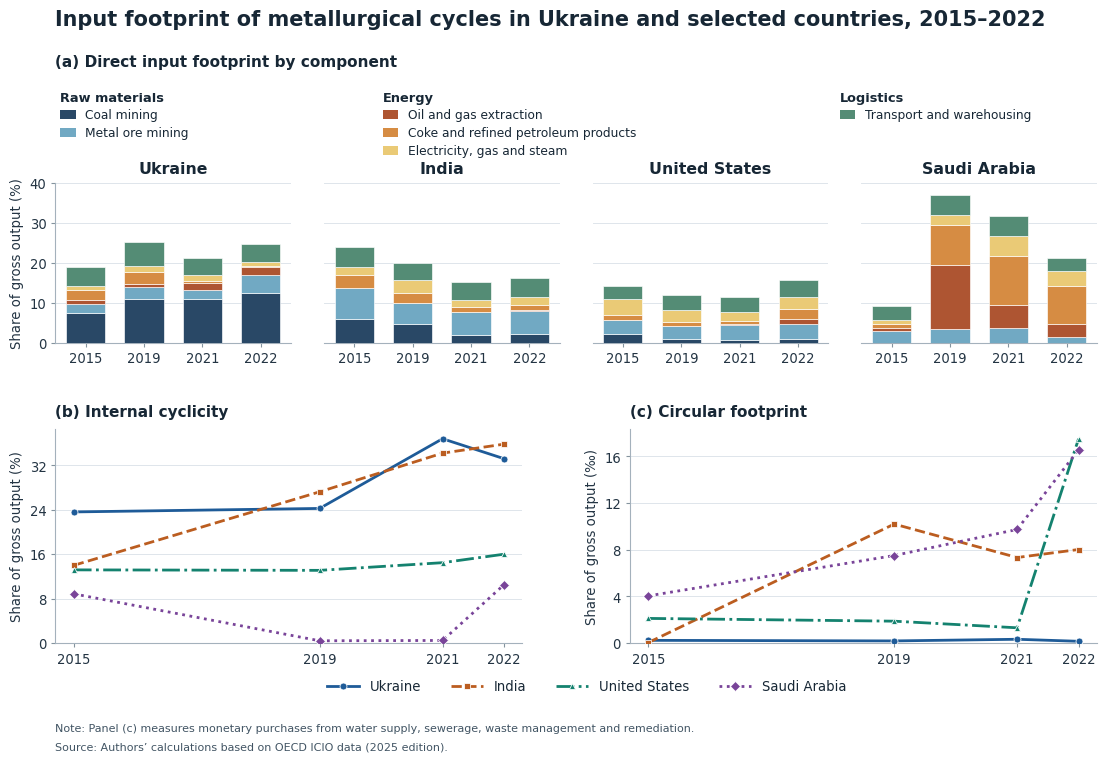

In [236]:
# Figure 2. Build, export, and display the figure in this cell.
from io import BytesIO

from IPython import get_ipython
from IPython.display import Image as NotebookImage
from matplotlib.patches import Patch
from matplotlib.ticker import MaxNLocator

shell = get_ipython()
in_notebook = shell is not None and getattr(shell, "kernel", None) is not None
if in_notebook:
    shell.run_line_magic("matplotlib", "inline")

import matplotlib.pyplot as plt

country_styles = {
    "UKR": ("#1E5B98", "o", "-"),
    "IND": ("#BB5D20", "s", "--"),
    "USA": ("#14826F", "^", "-."),
    "SAU": ("#794499", "D", ":"),
}

with plt.rc_context({
    "font.family": "DejaVu Sans",
    "font.size": 9.5,
    "axes.labelcolor": "#233443",
    "text.color": "#172735",
    "xtick.color": "#233443",
    "ytick.color": "#233443",
    "pdf.fonttype": 42,
    "axes.spines.top": False,
    "axes.spines.right": False,
}):
    fig = plt.figure(figsize=(11.6, 7.8), facecolor="white")
    top = fig.add_gridspec(
        1, 4, left=.082, right=.98, bottom=.55, top=.755, wspace=.14
    )
    bottom = fig.add_gridspec(
        1, 2, left=.082, right=.98, bottom=.165, top=.44, wspace=.23
    )

    figure2_data = figure_2_table.set_index(["country", "year"])
    maximum = 100 * figure_2_table["selected_direct_components_share"].max()
    y_max = max(10, 10 * np.ceil(maximum * 1.04 / 10))

    bar_axes = []
    for index, country in enumerate(COUNTRIES):
        ax = fig.add_subplot(top[0, index], sharey=bar_axes[0] if bar_axes else None)
        bar_axes.append(ax)
        series = figure2_data.loc[country].loc[list(YEARS)]
        offsets = np.arange(len(YEARS))
        cumulative = np.zeros(len(YEARS))

        for metric, (label, _, color) in figure2_components.items():
            values = 100 * series[metric].to_numpy()
            ax.bar(
                offsets, values, bottom=cumulative, width=.67, color=color,
                edgecolor="white", linewidth=.45, label=label, zorder=3,
            )
            cumulative += values

        ax.set_ylim(0, y_max)
        ax.set_yticks(np.arange(0, y_max + 1, 10))
        ax.set_xticks(offsets, [str(year) for year in YEARS])
        ax.set_title(COUNTRY_NAMES[country], fontweight="semibold", pad=7)

        if index:
            ax.tick_params(axis="y", left=False, labelleft=False)
            ax.spines["left"].set_visible(False)
        else:
            ax.set_ylabel("Share of gross output (%)")

    line_panels = [
        (
            "own_sector_direct_share", 100, "Share of gross output (%)",
            "(b) Internal cyclicity",
        ),
        (
            "circular_footprint_per_mille", 1, "Share of gross output (‰)",
            "(c) Circular footprint",
        ),
    ]
    line_axes = []
    for index, (metric, scale, ylabel, title) in enumerate(line_panels):
        ax = fig.add_subplot(bottom[0, index])
        line_axes.append(ax)

        for country in COUNTRIES:
            values = figure2_data.loc[country].loc[list(YEARS), metric]
            color, marker, linestyle = country_styles[country]
            ax.plot(
                YEARS, scale * values.to_numpy(), color=color, marker=marker,
                linestyle=linestyle, linewidth=2, markersize=5,
                label=COUNTRY_NAMES[country], markeredgecolor="white",
                markeredgewidth=.55, zorder=3,
            )

        ax.set_title(title, loc="left", fontweight="semibold", fontsize=11, pad=9)
        ax.set_ylabel(ylabel)
        ax.set_xticks(YEARS, [str(year) for year in YEARS])
        ax.set_xlim(min(YEARS) - .3, max(YEARS) + .3)
        ax.set_ylim(bottom=0)
        ax.yaxis.set_major_locator(MaxNLocator(nbins=5))

    for ax in (*bar_axes, *line_axes):
        ax.grid(axis="y", color="#DCE3E9", linewidth=.65, zorder=0)
        ax.set_axisbelow(True)
        ax.tick_params(length=3, color="#84939E")
        for pos in ("bottom", "left"):
            ax.spines[pos].set_color("#A4B1BC")

    fig.text(
        .082, .957,
        "Input footprint of metallurgical cycles in Ukraine and selected countries, 2015–2022",
        fontsize=15, fontweight="bold", ha="left",
    )
    fig.text(
        .082, .904, "(a) Direct input footprint by component",
        fontsize=11, fontweight="semibold",
    )

    group_positions = (.082, .360, .754)
    for (group_name, group), position in zip(figure2_groups.items(), group_positions):
        handles = [Patch(facecolor=color, label=label) for label, _, color in group.values()]
        legend = fig.legend(
            handles=handles, title=group_name, alignment="left", loc="upper left",
            bbox_to_anchor=(position, .878), fontsize=8.8, title_fontsize=9.3,
            frameon=False, borderaxespad=0, handlelength=1.25, labelspacing=.40,
        )
        legend.get_title().set_fontweight("semibold")

    fig.legend(
        *line_axes[0].get_legend_handles_labels(), ncol=4, frameon=False,
        loc="center", bbox_to_anchor=(.54, .109), columnspacing=2.3, handlelength=2.4,
    )
    fig.text(
        .082, .052,
        "Note: Panel (c) measures monetary purchases from water supply, sewerage, "
        "waste management and remediation.",
        fontsize=8, color="#415463",
    )
    fig.text(
        .082, .028, "Source: Authors’ calculations based on OECD ICIO data (2025 edition).",
        fontsize=8, color="#415463",
    )

    figure_2_png = OUTPUT_DIR / "Figure_2_Input_Footprint.png"
    figure_2_pdf = OUTPUT_DIR / "Figure_2_Input_Footprint.pdf"
    fig.savefig(figure_2_png, dpi=400, facecolor="white")
    fig.savefig(figure_2_pdf, facecolor="white")

    if in_notebook:
        plt.show()
    else:
        with BytesIO() as preview:
            fig.savefig(preview, format="png", dpi=110, facecolor="white")
            display(NotebookImage(data=preview.getvalue(), format="png"))
    plt.close(fig)

In [238]:
# Figure 3. Calculate output destinations as shares of C24A gross output.
figure_3_components = {
    "domestic_other_intermediate_sales_share": "Production footprint",
    "own_sector_direct_share": "Internal cyclicity",
    "reported_export_share": "Export footprint",
    "domestic_final_use_share": "Domestic final use",
}

figure_3_cases = pd.MultiIndex.from_product([COUNTRIES, YEARS], names=["country", "year"])
figure_3_table = direct.set_index(["country", "year"]).loc[figure_3_cases, [
    "steel_gross_output", *figure_3_components, "sales_residual_share",
    "domestic_fabricated_metals_destination_share", "domestic_water_waste_destination_share",
]].reset_index()
figure_3_table.insert(1, "country_name", figure_3_table["country"].map(COUNTRY_NAMES))
figure_3_table["accounted_output_share"] = figure_3_table[list(figure_3_components)].sum(axis=1)

# Retain the original output denominator and check the recorded balance gap.
figure_3_balance_gap = 1 - figure_3_table["accounted_output_share"]
np.testing.assert_allclose(
    figure_3_balance_gap, figure_3_table["sales_residual_share"], rtol=0, atol=1e-12,
)
if figure_3_balance_gap.abs().gt(BALANCE_REL_TOL).any():
    raise ValueError("Figure 3: output balance exceeds the tolerance in Data preparation.")

figure_3_preview = figure_3_table[["country_name", "year"]].rename(
    columns={"country_name": "Country", "year": "Year"}
)
for metric, label in figure_3_components.items():
    figure_3_preview[f"{label} (%)"] = 100 * figure_3_table[metric]
figure_3_preview["Balance gap (pp)"] = 100 * figure_3_balance_gap

figure_3_csv = OUTPUT_DIR / "figure_3_output_destinations.csv"
figure_3_table.to_csv(figure_3_csv, index=False, encoding="utf-8-sig")
display(figure_3_preview.round(4))

,Country,Year,Production footprint (%),Internal cyclicity (%),Export footprint (%),Domestic final use (%),Balance gap (pp)
0,Ukraine,2015,37.1417,23.6226,39.2080,0.0276,0.0001
1,Ukraine,2019,52.3989,24.2520,23.3058,0.0433,-0.0000
2,Ukraine,2021,26.2325,36.8001,36.9434,0.0240,0.0000
3,Ukraine,2022,31.7823,33.2107,34.9499,0.0571,0.0001
4,India,2015,69.3364,14.0098,10.9322,5.7216,0.0001
5,India,2019,64.2379,27.2436,7.7770,0.7415,0.0000
6,India,2021,54.6714,34.2097,10.1771,0.9418,0.0000
7,India,2022,55.3415,35.8249,7.9335,0.9001,0.0000
8,United States,2015,75.5427,13.1914,10.0553,1.2107,-0.0001
9,United States,2019,78.5131,13.1040,7.3589,1.0240,-0.0000


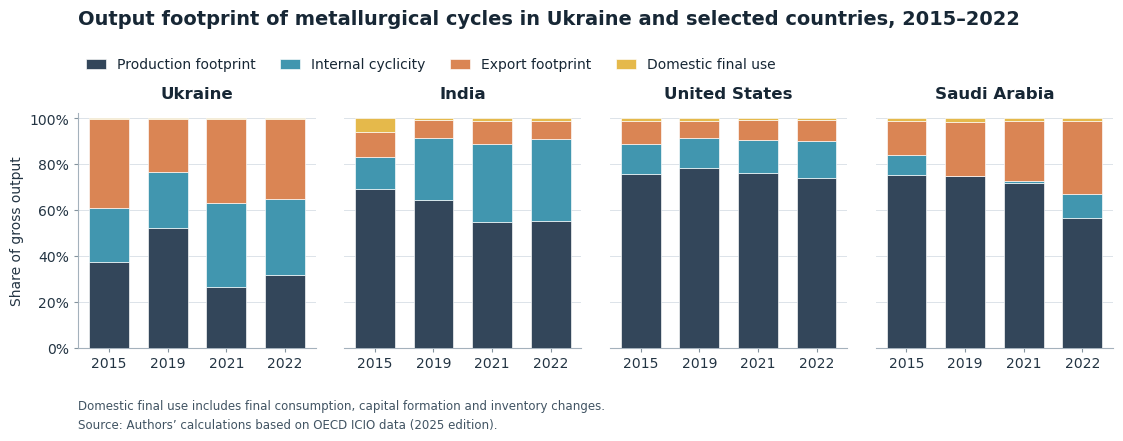

In [240]:
# Figure 3. Build, export, and display the figure in this cell.
from io import BytesIO

from IPython import get_ipython
from IPython.display import Image as NotebookImage
from matplotlib.ticker import PercentFormatter

figure_3_shell = get_ipython()
figure_3_inline = figure_3_shell is not None and getattr(figure_3_shell, "kernel", None) is not None
if figure_3_inline:
    figure_3_shell.run_line_magic("matplotlib", "inline")

import matplotlib.pyplot as plt

figure_3_colors = {
    "domestic_other_intermediate_sales_share": "#33465A",
    "own_sector_direct_share": "#4196AF",
    "reported_export_share": "#DA8554",
    "domestic_final_use_share": "#E5B94B",
}

with plt.rc_context({"font.family": "DejaVu Sans", "font.size": 10,
                     "axes.labelcolor": "#233443", "text.color": "#172735",
                     "xtick.color": "#233443", "ytick.color": "#233443",
                     "pdf.fonttype": 42, "axes.spines.top": False, "axes.spines.right": False}):
    figure_3, axes = plt.subplots(1, len(COUNTRIES), sharey=True, figsize=(11.6, 4.65), facecolor="white")
    figure_3.subplots_adjust(left=.088, right=.98, bottom=.225, top=.73, wspace=.12)
    figure_3_data = figure_3_table.set_index(["country", "year"])
    positions = np.arange(len(YEARS))
    for ax, country in zip(axes, COUNTRIES):
        series = figure_3_data.loc[country].loc[list(YEARS)]
        positive = np.zeros(len(YEARS))
        negative = np.zeros(len(YEARS))
        for metric, label in figure_3_components.items():
            values = series[metric].to_numpy()
            bottom = np.where(values >= 0, positive, negative)
            ax.bar(positions, values, bottom=bottom, width=.68, label=label,
                   color=figure_3_colors[metric], edgecolor="white", linewidth=.45, zorder=3)
            positive += np.maximum(values, 0)
            negative += np.minimum(values, 0)
        ax.set_title(COUNTRY_NAMES[country], fontweight="semibold", pad=10)
        ax.set_xticks(positions, [str(year) for year in YEARS])
        ax.set_yticks(np.linspace(0, 1, 6))
        ax.yaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=0))
        ax.grid(axis="y", color="#DCE3E9", linewidth=.7)
        ax.set_axisbelow(True)
        ax.tick_params(length=3, color="#84939E")
        for spine in ("left", "bottom"):
            ax.spines[spine].set_color("#A4B1BC")
        if ax is not axes[0]:
            ax.tick_params(axis="y", left=False, labelleft=False)
            ax.spines["left"].set_visible(False)

    positive_limit = figure_3_table[list(figure_3_components)].clip(lower=0).sum(axis=1).max()
    negative_limit = figure_3_table[list(figure_3_components)].clip(upper=0).sum(axis=1).min()
    axes[0].set_ylim(min(0, 1.08 * negative_limit), max(1.025, 1.01 * positive_limit))
    axes[0].set_ylabel("Share of gross output")
    figure_3.text(.088, .92, "Output footprint of metallurgical cycles in Ukraine and selected countries, 2015–2022",
                  fontsize=14, fontweight="bold")
    figure_3.legend(*axes[0].get_legend_handles_labels(), ncol=4, frameon=False,
                    loc="upper left", bbox_to_anchor=(.084, .875), columnspacing=1.8,
                    handlelength=1.4)
    figure_3.text(.088, .092, "Domestic final use includes final consumption, capital formation and inventory changes.",
                  fontsize=8.5, color="#415463")
    figure_3.text(.088, .052, "Source: Authors’ calculations based on OECD ICIO data (2025 edition).",
                  fontsize=8.5, color="#415463")

    figure_3_png = INPUT.parent / "Figure_3_Output_Footprint.png"
    figure_3_pdf = INPUT.parent / "Figure_3_Output_Footprint.pdf"
    figure_3.savefig(figure_3_png, dpi=400, facecolor="white")
    figure_3.savefig(figure_3_pdf, facecolor="white")
    if figure_3_inline:
        plt.show()
    else:
        with BytesIO() as preview:
            figure_3.savefig(preview, format="png", dpi=110, facecolor="white")
            display(NotebookImage(data=preview.getvalue(), format="png"))
    plt.close(figure_3)

In [ ]:
def solve_domestic_model(block, requested_sectors):
    x = block.loc["OUTPUT", requested_sectors].astype(float)
    if x.isna().any() or x.lt(0).any():
        raise ValueError("Model requires nonmissing, nonnegative output by sector")
    inactive = x.index[x.eq(0)]
    z_all = block.loc[sectors, sectors]
    if z_all.loc[inactive].ne(0).any().any() or z_all.loc[:, inactive].ne(0).any().any():
        raise ValueError("A zero-output sector has nonzero domestic flows")

    active = x.index[x.gt(0)]
    x = x.loc[active]
    a = block.loc[active, active].div(x, axis="columns")
    matrix = a.to_numpy()
    rho = np.abs(np.linalg.eigvals(matrix)).max()
    if rho >= 1:
        raise ValueError(f"Nonproductive domestic coefficient matrix (rho={rho:.6g})")
    identity = np.eye(len(active))
    inverse = np.linalg.solve(identity - matrix, identity)
    np.testing.assert_allclose((identity - matrix) @ inverse, identity, rtol=0, atol=1e-10)
    l = pd.DataFrame(inverse, index=active, columns=active)
    return x, a, l, rho


model_rows = []
matrix_frames = []
requirement_frames = []
dependence_frames = []
models = {}
for (country, year), block in blocks.items():
    requested_models = {"common12": common_sectors}
    if block.loc["OUTPUT", sectors].notna().all():
        requested_models["full_available"] = sectors
    for scope, requested in requested_models.items():
        x, a, l, rho = solve_domestic_model(block, requested)
        models[country, year, scope] = (x, a, l)
        column = l[FOCUS]
        own = l.loc[FOCUS, FOCUS]
        external = column.drop(FOCUS)
        components = external.groupby(sector_group).sum()
        np.testing.assert_allclose(
            [external.sum(), components.sum()], column.sum() - own, rtol=0, atol=1e-10
        )
        dimensions = {"country": country, "year": year, "scope": scope}
        model_rows.append({
            **dimensions, "active_sector_count": len(x), "spectral_radius": rho,
            "output_multiplier": column.sum(), "own_sector_requirement": own,
            "own_sector_feedback_requirement": own - 1,
            "other_domestic_sector_requirement": external.sum(),
            "es_identity_gap": external.sum() - (column.sum() - own),
        })
        requirement_frames.append(
            column.rename("output_requirement").rename_axis("supplier_sector").reset_index().assign(**dimensions)
        )
        dependence_frames.append(
            components.rename("other_domestic_sector_requirement")
            .rename_axis("component").reset_index().assign(**dimensions)
        )
        matrix_frames.append(
            pd.DataFrame({
                "supplier_sector": np.repeat(x.index.to_numpy(), len(x)),
                "buyer_sector": np.tile(x.index.to_numpy(), len(x)),
                "direct_input_coefficient": a.to_numpy().ravel(),
                "total_output_requirement": l.to_numpy().ravel(),
            }).assign(**dimensions)
        )

output_models = pd.DataFrame(model_rows)
matrices = pd.concat(matrix_frames, ignore_index=True)
requirements = pd.concat(requirement_frames, ignore_index=True)
dependence_by_component = pd.concat(dependence_frames, ignore_index=True)
scope_check = output_models.query("year == 2022").pivot(
    index="country", columns="scope",
    values=["output_multiplier", "own_sector_requirement", "other_domestic_sector_requirement"],
).reindex(COUNTRIES)
display(scope_check.round(4))

In [ ]:
# Figure 4. Divide each industry’s GVA by its own gross output.
figure_4_sectors = {
    "COAL": "Coal mining",
    "OILGAS": "Oil and gas extraction",
    "ORES": "Metal ore mining",
    "COKE": "Coke and refined petroleum products",
    "METAL": "Basic iron and steel",
    "FABMET": "Fabricated metal products",
}
va_industry_frames = []
va_direct_by_case = {}
for (country, year), prepared in prepared_blocks.items():
    gross_output = prepared["x"]
    industry_gva = prepared["va"]
    direct_share = ratio(industry_gva, gross_output)
    va_direct_by_case[country, year] = direct_share
    va_industry_frames.append(pd.DataFrame({
        "country": country, "year": year, "sector": sectors,
        "va_direct_share": direct_share, "gross_output": gross_output, "gva": industry_gva,
    }))

va_industry = pd.concat(va_industry_frames, ignore_index=True)
# Retain the original export covering all 13 industry groups.
va_direct = va_industry[["country", "year", "sector", "va_direct_share"]].copy()

figure_4_cases = pd.MultiIndex.from_product(
    [COUNTRIES, YEARS, figure_4_sectors], names=["country", "year", "sector"],
)
figure_4_table = va_industry.set_index(["country", "year", "sector"]).loc[figure_4_cases].reset_index()
figure_4_table.insert(1, "country_name", figure_4_table["country"].map(COUNTRY_NAMES))
figure_4_codes = mapping.set_index("sector")["oecd_icio_code"]
figure_4_table.insert(4, "oecd_icio_code", figure_4_table["sector"].map(figure_4_codes))
figure_4_table.insert(5, "sector_name", figure_4_table["sector"].map(figure_4_sectors))
figure_4_table["va_direct_share_pct"] = 100 * figure_4_table["va_direct_share"]
figure_4_table["status"] = np.where(figure_4_table["gross_output"].eq(0), "zero_output", "observed")

figure_4_csv = OUTPUT_DIR / "figure_4_direct_gva_table.csv"
figure_4_table.to_csv(figure_4_csv, index=False, encoding="utf-8-sig")
figure_4_preview = figure_4_table.pivot(
    index=["country", "year"], columns="sector", values="va_direct_share_pct",
).reindex(pd.MultiIndex.from_product([COUNTRIES, YEARS], names=["country", "year"]))
figure_4_preview = (
    figure_4_preview[list(figure_4_sectors)]
    .rename(columns=figure_4_sectors, index=COUNTRY_NAMES, level="country")
    .rename_axis(index=["Country", "Year"], columns=None)
)
display(figure_4_preview.round(2).astype(object).where(figure_4_preview.notna(), "—"))

In [ ]:
# Figure 4. Build, export, and display the figure in this cell.
from io import BytesIO

from IPython import get_ipython
from IPython.display import Image as NotebookImage
from matplotlib.ticker import PercentFormatter

figure_4_shell = get_ipython()
figure_4_inline = figure_4_shell is not None and getattr(figure_4_shell, "kernel", None) is not None
if figure_4_inline:
    figure_4_shell.run_line_magic("matplotlib", "inline")

import matplotlib.pyplot as plt

figure_4_styles = {
    "UKR": ("#1E5B98", "o", "-"),
    "IND": ("#BB5D20", "s", "--"),
    "USA": ("#14826F", "^", "-."),
    "SAU": ("#794499", "D", ":"),
}

with plt.rc_context({"font.family": "DejaVu Sans", "font.size": 10,
                     "axes.labelcolor": "#233443", "text.color": "#172735",
                     "xtick.color": "#233443", "ytick.color": "#233443",
                     "pdf.fonttype": 42, "axes.spines.top": False, "axes.spines.right": False}):
    figure_4, panels = plt.subplots(2, 3, sharex=True, sharey=True, figsize=(11.6, 6.95),
                                    facecolor="white")
    figure_4.subplots_adjust(left=.085, right=.97, bottom=.175, top=.79, wspace=.20, hspace=.45)
    figure_4_data = figure_4_table.set_index(["sector", "country", "year"]).sort_index()
    for index, (ax, (sector, label)) in enumerate(zip(panels.flat, figure_4_sectors.items())):
        for country in COUNTRIES:
            values = figure_4_data.loc[(sector, country), "va_direct_share"].reindex(YEARS)
            color, marker, linestyle = figure_4_styles[country]
            ax.plot(YEARS, values.to_numpy(), color=color, marker=marker, linestyle=linestyle,
                    linewidth=1.8, markersize=5.3, markeredgecolor="white", markeredgewidth=.65,
                    label=COUNTRY_NAMES[country], zorder=3)
        ax.set_title(f"({chr(97 + index)}) {label}", loc="left", fontweight="semibold", fontsize=10.1, pad=9)
        ax.set_xticks(YEARS, [str(year) for year in YEARS])
        ax.set_xlim(min(YEARS) - .35, max(YEARS) + .35)
        ax.grid(axis="y", color="#DCE3E9", linewidth=.7)
        ax.set_axisbelow(True)
        ax.tick_params(length=3, color="#84939E", labelbottom=True)
        for spine in ("left", "bottom"):
            ax.spines[spine].set_color("#A4B1BC")

    min_ratio = min(0, np.floor(5 * figure_4_table["va_direct_share"].min()) / 5)
    max_ratio = max(1, np.ceil(5 * figure_4_table["va_direct_share"].max()) / 5)
    panels[0, 0].set_yticks(np.arange(min_ratio, max_ratio + .1, .2))
    panels[0, 0].set_ylim(min_ratio - .017, max_ratio + .025)
    panels[0, 0].yaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=0))
    figure_4.text(.017, .49, "Direct GVA share in industry gross output", rotation=90, va="center")
    figure_4.text(.085, .948, "Direct GVA share in the metallurgical cycles of Ukraine and selected countries, 2015–2022",
                  fontsize=14.5, fontweight="bold")
    figure_4.legend(*panels[0, 0].get_legend_handles_labels(), ncol=4, frameon=False,
                    loc="upper left", bbox_to_anchor=(.08, .915), columnspacing=2.2, handlelength=2.6)
    figure_4.text(.085, .082, "Note: The share for coal mining in Saudi Arabia is undefined because recorded gross output is zero.",
                  fontsize=8.5, color="#415463")
    figure_4.text(.085, .045, "Source: Authors’ calculations based on OECD ICIO data (2025 edition).",
                  fontsize=8.5, color="#415463")

    figure_4_png = INPUT.parent / "Figure_4_Direct_GVA_Share.png"
    figure_4_pdf = INPUT.parent / "Figure_4_Direct_GVA_Share.pdf"
    figure_4.savefig(figure_4_png, dpi=400, facecolor="white")
    figure_4.savefig(figure_4_pdf, facecolor="white")
    if figure_4_inline:
        plt.show()
    else:
        with BytesIO() as preview:
            figure_4.savefig(preview, format="png", dpi=110, facecolor="white")
            display(NotebookImage(data=preview.getvalue(), format="png"))
    plt.close(figure_4)

In [ ]:
va_summary_frames = []
va_contribution_frames = []
for (country, year), block in blocks.items():
    v_source = va_direct_by_case[country, year]
    key = (country, year, "full_available")
    if key not in models:
        continue
    x, _, l = models[key]
    v = v_source.loc[x.index]
    if v.isna().any():
        continue
    va_matrix = l.mul(v, axis="index")
    total = va_matrix.sum(axis=0)
    own = pd.Series(np.diag(va_matrix), index=x.index)
    feedback = own - v
    outside = total - own
    norm = ratio(total, v)
    np.testing.assert_allclose(v + feedback + outside, total, rtol=0, atol=1e-10)
    np.testing.assert_allclose(
        (norm * v).dropna(), total.loc[norm.dropna().index], rtol=0, atol=1e-10
    )

    imp = block.loc["IMP_IC", x.index].astype(float) / x
    tls = block.loc["TLS", x.index].astype(float) / x
    import_requirement = l.T @ imp
    tax_requirement = l.T @ tls
    unit_residual = 1 - total - import_requirement - tax_requirement
    if not unit_residual.isna().any():
        # Source values are rounded and aggregated.
        np.testing.assert_allclose(unit_residual, 0, rtol=0, atol=5e-5)

    va_summary_frames.append(pd.DataFrame({
        "country": country, "year": year, "scope": "full_available", "sector": x.index,
        "va_direct": v, "va_own_feedback": feedback, "va_other_domestic": outside,
        "va_total_domestic": total, "va_multiplier_normalized": norm,
        "va_other_share_in_total": ratio(outside, total),
        "imported_intermediate_requirement": import_requirement,
        "taxes_less_subsidies_requirement": tax_requirement, "unit_balance_residual": unit_residual,
    }))
    va_contribution_frames.append(
        va_matrix[FOCUS].rename("va_contribution").rename_axis("supplier_sector")
        .reset_index().assign(country=country, year=year, scope="full_available")
    )

va_all_sectors = pd.concat(va_summary_frames, ignore_index=True)
va_by_supplier = pd.concat(va_contribution_frames, ignore_index=True)
va_steel = va_all_sectors.loc[va_all_sectors["sector"].eq(FOCUS)].copy()
va_display = ["va_direct", "va_own_feedback", "va_other_domestic", "va_total_domestic",
              "va_multiplier_normalized", "va_other_share_in_total"]
display(va_steel.set_index("country").loc[list(COUNTRIES), va_display].round(4))

In [ ]:
# Tables A1 and A2, on the full domestic industry model.
from IPython.display import Markdown
figure_5_cases = pd.MultiIndex.from_product([COUNTRIES, YEARS], names=["country", "year"])
a1_requirements = (
    requirements.query("scope == 'full_available'")
    .pivot(index=["country", "year"], columns="supplier_sector", values="output_requirement")
    .reindex(index=figure_5_cases, columns=sectors)
)
# Fill only the structural gaps for verified inactive supplying industries.
for key, case in prepared_blocks.items():
    inactive = case["x"].index[case["x"].eq(0)]
    if len(inactive):
        a1_requirements.loc[key, inactive] = 0.0
if a1_requirements.isna().any().any():
    raise ValueError("Table A1 has missing active-industry requirements.")

a1_totals = output_models.query("scope == 'full_available'").set_index(["country", "year"])
a1_totals = a1_totals.loc[figure_5_cases, [
    "scope", "active_sector_count", "own_sector_requirement",
    "other_domestic_sector_requirement", "output_multiplier",
]]
table_a1 = a1_requirements.join(a1_totals).reset_index()
table_a1.insert(1, "country_name", table_a1["country"].map(COUNTRY_NAMES))
np.testing.assert_allclose(
    table_a1[sectors].sum(axis=1), table_a1["output_multiplier"], rtol=0, atol=1e-10,
)
np.testing.assert_allclose(
    table_a1[FOCUS], table_a1["own_sector_requirement"], rtol=0, atol=1e-10,
)

a2_cases = pd.MultiIndex.from_product(
    [COUNTRIES, YEARS, figure_4_sectors], names=["country", "year", "sector"],
)
a2_results = va_all_sectors.set_index(["country", "year", "sector"]).drop(columns="scope")
a2_output = va_industry.set_index(["country", "year", "sector"])["gross_output"]
table_a2 = a2_results.reindex(a2_cases).join(a2_output).reset_index()
table_a2.insert(1, "country_name", table_a2["country"].map(COUNTRY_NAMES))
table_a2.insert(4, "sector_name", table_a2["sector"].map(figure_4_sectors))
table_a2.insert(5, "oecd_icio_code", table_a2["sector"].map(mapping.set_index("sector")["oecd_icio_code"]))
table_a2.insert(6, "scope", "full_available")
table_a2["status"] = np.where(
    table_a2["gross_output"].eq(0), "zero_output",
    np.where(table_a2["va_direct"].gt(0), "observed", "nonpositive_direct_gva"),
)
table_a2["va_indirect_domestic"] = table_a2["va_own_feedback"] + table_a2["va_other_domestic"]
active_a2 = table_a2["gross_output"].gt(0)
active_metrics = ["va_direct", "va_own_feedback", "va_other_domestic", "va_total_domestic"]
if table_a2.loc[active_a2, active_metrics].isna().any().any():
    raise ValueError("Table A2 has missing active-industry GVA estimates.")
np.testing.assert_allclose(
    table_a2.loc[active_a2, "va_direct"] + table_a2.loc[active_a2, "va_indirect_domestic"],
    table_a2.loc[active_a2, "va_total_domestic"], rtol=0, atol=1e-10,
)

figure_5a_table = table_a1[["country", "country_name", "year", "own_sector_requirement",
                           "other_domestic_sector_requirement", "output_multiplier"]].copy()
figure_5b_table = table_a2.loc[table_a2["sector"].eq(FOCUS), [
    "country", "country_name", "year", *active_metrics, "va_multiplier_normalized",
]].reset_index(drop=True)

figure_5_exports = {
    "Table_A1_Output_Multipliers": table_a1,
    "Table_A2_GVA_Multipliers": table_a2,
}
for name, frame in figure_5_exports.items():
    frame.to_csv(OUTPUT_DIR / f"{name}.csv", index=False, encoding="utf-8-sig")

a1_labels = mapping.set_index("sector")["csv_label"].to_dict()
a1_labels["output_multiplier"] = "Total output multiplier"
table_a1_preview = table_a1.set_index(["country_name", "year"])[[*sectors, "output_multiplier"]].T
table_a1_preview = table_a1_preview.rename(index=a1_labels)
table_a2_preview = (
    table_a2.pivot(index="sector", columns=["country", "year"], values="va_multiplier_normalized")
    .reindex(index=list(figure_4_sectors), columns=figure_5_cases)
    .rename(index=figure_4_sectors, columns=COUNTRY_NAMES, level=0)
)
display(Markdown("**Table A1. Output requirements by supplying industry and total output multiplier for C24A**"))
display(table_a1_preview.round(3))
display(Markdown("**Table A2. Normalized GVA multipliers by focal industry**"))
display(table_a2_preview.round(3).astype(object).where(table_a2_preview.notna(), "—"))

In [ ]:
# Figure 5. Output multiplier, GVA multiplier and structure of the GVA multiplier for C24A.
from io import BytesIO

from IPython import get_ipython
from IPython.display import Image as NotebookImage
from matplotlib.ticker import MultipleLocator

figure_5_shell = get_ipython()
figure_5_inline = figure_5_shell is not None and getattr(figure_5_shell, "kernel", None) is not None
if figure_5_inline:
    figure_5_shell.run_line_magic("matplotlib", "inline")

import matplotlib.pyplot as plt

figure_5_country_colors = {
    "UKR": "#1E5B98", "IND": "#BB5D20", "USA": "#14826F", "SAU": "#794499",
}
figure_5_gva_styles = {
    "va_direct": ("Direct GVA", "#33465A"),
    "va_own_feedback": ("Indirect GVA", "#4196AF"),
    "va_other_domestic": ("GVA in other domestic industries", "#DA8554"),
}
figure_5_segment_label_colors = {
    "va_direct": "white", "va_other_domestic": "#172735",
}

with plt.rc_context({"font.family": "DejaVu Sans", "font.size": 9.5,
                     "axes.labelcolor": "#233443", "text.color": "#172735",
                     "xtick.color": "#233443", "ytick.color": "#233443",
                     "pdf.fonttype": 42, "axes.spines.top": False, "axes.spines.right": False}):
    figure_5 = plt.figure(figsize=(13.0, 7.6), facecolor="white")
    top_grid = figure_5.add_gridspec(1, 2, left=.087, right=.98, bottom=.54, top=.81, wspace=.25)
    lower_grid = figure_5.add_gridspec(1, 4, left=.087, right=.98, bottom=.145, top=.355, wspace=.14)
    year_positions = np.arange(len(YEARS))
    group_bar_step = .8 / len(COUNTRIES)
    country_offsets = (np.arange(len(COUNTRIES)) - (len(COUNTRIES) - 1) / 2) * group_bar_step
    top_axes = []
    panels = [
        (figure_5a_table, "output_multiplier", "(a) Output multiplier", "Output per unit of final demand", .5),
        (figure_5b_table, "va_total_domestic", "(b) GVA multiplier", "Domestic GVA per unit of final demand", .2),
    ]
    for index, (frame, column, title, unit, interval) in enumerate(panels):
        ax = figure_5.add_subplot(top_grid[0, index])
        top_axes.append(ax)
        series = frame.set_index(["country", "year"])[column]
        for country, offset in zip(COUNTRIES, country_offsets):
            values = series.loc[country].reindex(YEARS).to_numpy()
            bars = ax.bar(year_positions + offset, values, width=group_bar_step * .9,
                          color=figure_5_country_colors[country], label=COUNTRY_NAMES[country], zorder=3)
            ax.bar_label(bars, fmt="%.2f", padding=3, fontsize=7.2)
        ax.set_ylim(0, series.max() * 1.15)
        ax.set_title(title, loc="left", fontweight="semibold", fontsize=11, pad=8)
        ax.set_ylabel(unit)
        ax.set_xticks(year_positions, [str(year) for year in YEARS])
        ax.set_xlim(-.5, len(YEARS) - .5)
        ax.yaxis.set_major_locator(MultipleLocator(interval))

    gva_axes = []
    gva_by_case = figure_5b_table.set_index(["country", "year"])
    for index, country in enumerate(COUNTRIES):
        ax = figure_5.add_subplot(lower_grid[0, index], sharey=gva_axes[0] if gva_axes else None)
        gva_axes.append(ax)
        series = gva_by_case.loc[country].reindex(YEARS)
        positive = np.zeros(len(YEARS))
        negative = np.zeros(len(YEARS))
        for metric, (label, color) in figure_5_gva_styles.items():
            values = series[metric].to_numpy()
            base = np.where(values >= 0, positive, negative)
            bars = ax.bar(year_positions, values, bottom=base, width=.68, color=color,
                          edgecolor="white", linewidth=.45, label=label, zorder=3)
            if metric in figure_5_segment_label_colors:
                ax.bar_label(bars, fmt="%.2f", label_type="center", fontsize=8,
                             color=figure_5_segment_label_colors[metric])
            positive += np.maximum(values, 0)
            negative += np.minimum(values, 0)
        ax.set_title(COUNTRY_NAMES[country], fontweight="semibold", pad=6)
        ax.set_xticks(year_positions, [str(year) for year in YEARS])
        if index:
            ax.tick_params(axis="y", left=False, labelleft=False)
            ax.spines["left"].set_visible(False)
    gva_axes[0].set_ylabel("GVA per unit of final demand")
    gva_axes[0].yaxis.set_major_locator(MultipleLocator(.2))
    values = figure_5b_table[list(figure_5_gva_styles)]
    gva_limits = (
        min(0, 1.05 * values.clip(upper=0).sum(axis=1).min()),
        max(1, 1.05 * values.clip(lower=0).sum(axis=1).max()),
    )
    top_axes[1].set_ylim(gva_limits)
    gva_axes[0].set_ylim(gva_limits)

    for ax in (*top_axes, *gva_axes):
        ax.grid(axis="y", color="#DCE3E9", linewidth=.65)
        ax.set_axisbelow(True)
        ax.tick_params(length=3, color="#84939E")
        for pos in ("left", "bottom"):
            ax.spines[pos].set_color("#A4B1BC")

    figure_5.text(.087, .953, "Output and GVA multipliers in metallurgical cycles, 2015–2022",
                  fontsize=15, fontweight="bold")
    figure_5.legend(*top_axes[0].get_legend_handles_labels(), ncol=4, frameon=False,
                    loc="upper left", bbox_to_anchor=(.082, .923), columnspacing=2.1, handlelength=1.4)
    figure_5.text(.087, .453, "(c) Structure of GVA multiplier",
                  fontsize=11, fontweight="semibold")
    figure_5.legend(*gva_axes[0].get_legend_handles_labels(), ncol=3, frameon=False,
                    loc="upper left", bbox_to_anchor=(.082, .427), columnspacing=1.7, handlelength=1.4)
    figure_5.text(.087, .057, "Note: Calculations for Basic iron and steel (C24A). The components in (c) sum to the GVA multiplier in (b).",
                  fontsize=8.5, color="#415463")
    figure_5.text(.087, .031, "Source: Authors’ calculations based on OECD ICIO data (2025 edition).",
                  fontsize=8.5, color="#415463")

    figure_5_png = INPUT.parent / "Figure_5_Output_and_GVA_Multipliers.png"
    figure_5_pdf = INPUT.parent / "Figure_5_Output_and_GVA_Multipliers.pdf"
    figure_5.savefig(figure_5_png, dpi=400, facecolor="white")
    figure_5.savefig(figure_5_pdf, facecolor="white")
    if figure_5_inline:
        plt.show()
    else:
        with BytesIO() as preview:
            figure_5.savefig(preview, format="png", dpi=110, facecolor="white")
            display(NotebookImage(data=preview.getvalue(), format="png"))
    plt.close(figure_5)

In [ ]:
# Appendix B. Calculate own and other domestic output requirements for all six focal industries.
b2_component_sectors = {
    "raw_materials": ("COAL", "ORES", "METAL"),
    "energy": ("OILGAS", "COKE", "ELEC"),
    "logistics": ("TRANSP", "WAREH"),
    "services_and_other_industries": ("FABMET", "WASTE", "CONSTR", "TRADE", "OTHERS"),
}
b2_component_names = {
    "raw_materials": "Raw materials",
    "energy": "Energy",
    "logistics": "Logistics",
    "services_and_other_industries": "Services and other industries",
}
b2_sector_component = pd.Series({
    sector: component for component, members in b2_component_sectors.items() for sector in members
})
assert set(b2_sector_component.index) == set(sectors)
assert sum(map(len, b2_component_sectors.values())) == len(sectors)

b_cases = pd.MultiIndex.from_product([COUNTRIES, YEARS], names=["country", "year"])
b_focal_cases = pd.MultiIndex.from_product(
    [COUNTRIES, YEARS, figure_4_sectors], names=["country", "year", "sector"],
)
b_rows = []
for country, year in b_cases:
    _, _, leontief = models[country, year, "full_available"]
    for sector in leontief.columns.intersection(figure_4_sectors):
        requirements_j = leontief[sector]
        own = float(requirements_j.loc[sector])
        external = requirements_j.drop(sector)
        components = (
            external.groupby(b2_sector_component).sum().reindex(b2_component_names, fill_value=0.0)
        )
        total_output = float(requirements_j.sum())
        external_total = float(external.sum())
        np.testing.assert_allclose(
            [components.sum(), total_output - own], external_total, rtol=0, atol=1e-10,
        )
        b_rows.append({
            "country": country, "year": year, "sector": sector,
            "output_multiplier": total_output,
            "leontief_diagonal": own,
            "external_dependence": external_total,
            **components.to_dict(),
        })

b_results = pd.DataFrame(b_rows).set_index(["country", "year", "sector"])
b_meta_columns = ["country", "country_name", "year", "sector", "sector_name",
                  "oecd_icio_code", "scope", "gross_output", "status"]
b_meta = figure_4_table.set_index(["country", "year", "sector"])[
    ["country_name", "sector_name", "oecd_icio_code", "gross_output", "status"]
].reindex(b_focal_cases)
b_meta["scope"] = "full_available"
b_results = b_meta.join(b_results, validate="one_to_one").reset_index()
b_active = b_results["gross_output"].gt(0)
b_metrics = ["output_multiplier", "leontief_diagonal", "external_dependence", *b2_component_names]
assert b_results.loc[b_active, b_metrics].notna().all().all()
assert b_results.loc[~b_active, b_metrics].isna().all().all()

table_b1 = b_results[b_meta_columns + ["leontief_diagonal"]].copy()
table_b2 = b_results[b_meta_columns + b_metrics].copy()
figure_6_table = table_b2.loc[table_b2["sector"].eq(FOCUS)].copy()
figure_6_table = figure_6_table.set_index(["country", "year"]).loc[b_cases]

# Match Figure 6 to the independently assembled output multiplier table for C24A.
b_crosscheck = table_a1.set_index(["country", "year"]).loc[b_cases]
np.testing.assert_allclose(
    figure_6_table[["output_multiplier", "leontief_diagonal", "external_dependence"]],
    b_crosscheck[["output_multiplier", "own_sector_requirement", "other_domestic_sector_requirement"]],
    rtol=0, atol=1e-10,
)

figure_6_exports = {
    "Table_B1_Leontief_Diagonals": table_b1,
    "Table_B2_External_Dependence": table_b2,
}
for name, frame in figure_6_exports.items():
    frame.to_csv(OUTPUT_DIR / f"{name}.csv", index=False, encoding="utf-8-sig")

b1_preview = (
    table_b1.pivot(index="sector", columns=["country", "year"], values="leontief_diagonal")
    .reindex(index=list(figure_4_sectors), columns=b_cases)
    .rename(index=figure_4_sectors, columns=COUNTRY_NAMES, level=0)
)
b2_preview = (
    table_b2[["sector", "country", "year", "external_dependence", *b2_component_names]]
    .rename(columns={"external_dependence": "External dependence", **b2_component_names})
    .melt(id_vars=["sector", "country", "year"], var_name="Component")
    .pivot(index=["sector", "Component"], columns=["country", "year"], values="value")
    .reindex(pd.MultiIndex.from_product(
        [figure_4_sectors, ["External dependence", *b2_component_names.values()]],
        names=["sector", "Component"],
    )).reindex(columns=b_cases)
    .rename(index=figure_4_sectors, columns=COUNTRY_NAMES, level=0)
)
display(Markdown("**Table B1. Diagonal elements of the Leontief inverse by focal industry**"))
display(b1_preview.round(3).astype(object).where(b1_preview.notna(), "—"))
display(Markdown("**Table B2. External dependence and its components by focal industry**"))
display(b2_preview.round(3).astype(object).where(b2_preview.notna(), "—"))

In [ ]:
# Figure 6. Own and other domestic output requirements for basic iron and steel (C24A).
from matplotlib import patheffects

figure_6_shell = get_ipython()
figure_6_inline = figure_6_shell is not None and getattr(figure_6_shell, "kernel", None) is not None
if figure_6_inline:
    figure_6_shell.run_line_magic("matplotlib", "inline")

figure_6_component_colors = {
    "raw_materials": "#B35A2A",
    "energy": "#E3AA55",
    "logistics": "#5BA7BB",
    "services_and_other_industries": "#33465A",
}
figure_6_year_positions = np.arange(len(YEARS))
figure_6_year_labels = [str(year) for year in YEARS]

figure_6_stability_color = "#973470"
figure_6_left_limit = (0, figure_6_table["external_dependence"].max() * 1.24)
figure_6_right_limit = (.9, np.ceil((figure_6_table["leontief_diagonal"].max() + .08) / .2) * .2)

with plt.rc_context({"font.family": "DejaVu Sans", "font.size": 9.5,
                     "axes.labelcolor": "#233443", "text.color": "#172735",
                     "xtick.color": "#233443", "ytick.color": "#233443",
                     "pdf.fonttype": 42, "axes.spines.top": False, "axes.spines.right": False}):
    figure_6 = plt.figure(figsize=(11.8, 7.5), facecolor="white")
    grid = figure_6.add_gridspec(2, 2, left=.102, right=.9, bottom=.132, top=.823,
                                wspace=.28, hspace=.37)
    dependence_axes = []
    stability_axes = []
    for panel, country in zip(grid, COUNTRIES):
        ax = figure_6.add_subplot(panel)
        stability_ax = ax.twinx()
        dependence_axes.append(ax)
        stability_axes.append(stability_ax)
        case = figure_6_table.loc[country].reindex(YEARS)

        base = np.zeros(len(YEARS))
        for component, label in b2_component_names.items():
            values = case[component].to_numpy()
            ax.bar(figure_6_year_positions, values, bottom=base, width=.58,
                   color=figure_6_component_colors[component], edgecolor="white",
                   linewidth=.45, label=label, zorder=3)
            base += values

        stability_line, = stability_ax.plot(
            figure_6_year_positions, case["leontief_diagonal"], color=figure_6_stability_color,
            marker="o", markerfacecolor="white", markersize=5.8, markeredgewidth=1.6,
            linewidth=2.1, label="Internal stability", zorder=5,
        )
        stability_line.set_path_effects([patheffects.withStroke(linewidth=3.9, foreground="white")])
        for position, external, stability in zip(
            figure_6_year_positions, case["external_dependence"], case["leontief_diagonal"]
        ):
            ax.annotate(f"{external:.2f}", (position, external),
                        xytext=(-5, 3), textcoords="offset points", ha="right", va="bottom",
                        fontsize=8, zorder=6)
            stability_ax.annotate(f"{stability:.2f}", (position, stability),
                                  xytext=(5, 4), textcoords="offset points", ha="left", va="bottom",
                                  fontsize=8, color=figure_6_stability_color,
                                  path_effects=[patheffects.withStroke(linewidth=2.6, foreground="white")],
                                  zorder=6)

        ax.set_title(COUNTRY_NAMES[country], loc="left", fontweight="semibold", pad=7)
        ax.set_xticks(figure_6_year_positions, figure_6_year_labels)
        ax.set_xlim(-.55, len(YEARS) - .45)
        ax.set_ylim(figure_6_left_limit)
        ax.yaxis.set_major_locator(MultipleLocator(.25))
        ax.set_axisbelow(True)
        ax.grid(axis="y", color="#DCE3E9", linewidth=.65)
        ax.tick_params(length=3, color="#84939E")
        ax.spines["left"].set_color("#A4B1BC")
        ax.spines["bottom"].set_color("#A4B1BC")

        stability_ax.set_ylim(figure_6_right_limit)
        stability_ax.yaxis.set_major_locator(MultipleLocator(.2))
        stability_ax.tick_params(axis="y", colors=figure_6_stability_color, length=3)
        stability_ax.spines["right"].set_visible(True)
        stability_ax.spines["right"].set_color(figure_6_stability_color)
        stability_ax.spines["left"].set_visible(False)
        stability_ax.spines["bottom"].set_visible(False)

    figure_6.text(.102, .95, "Internal stability and external dependence of metallurgical cycles, 2015–2022",
                  fontsize=14.5, fontweight="bold")
    handles, labels = dependence_axes[0].get_legend_handles_labels()
    line_handles, line_labels = stability_axes[0].get_legend_handles_labels()
    figure_6.legend(handles + line_handles, labels + line_labels, ncol=5, frameon=False,
                    loc="upper left", bbox_to_anchor=(.097, .916), columnspacing=1.65, handlelength=1.7)
    figure_6.text(.031, .48, "External dependence", rotation=90, ha="center", va="center")
    figure_6.text(.962, .48, "Internal stability", rotation=270, ha="center", va="center",
                  color=figure_6_stability_color)
    figure_6.text(.102, .062, "Basic iron and steel (C24A). Both axes show output per unit of final demand.",
                  fontsize=8.5, color="#415463")
    figure_6.text(.102, .034, "Source: Authors’ calculations based on OECD ICIO data (2025 edition).",
                  fontsize=8.5, color="#415463")

    figure_6_png = INPUT.parent / "Figure_6_Internal_Stability_and_External_Dependence.png"
    figure_6_pdf = INPUT.parent / "Figure_6_Internal_Stability_and_External_Dependence.pdf"
    figure_6.savefig(figure_6_png, dpi=400, facecolor="white")
    figure_6.savefig(figure_6_pdf, facecolor="white")
    if figure_6_inline:
        plt.show()
    else:
        with BytesIO() as preview:
            figure_6.savefig(preview, format="png", dpi=110, facecolor="white")
            display(NotebookImage(data=preview.getvalue(), format="png"))
    plt.close(figure_6)

In [ ]:
from shutil import copy2

# Save Tables A1, A2, B1 and B2 as CSV files.
publication_tables = {**figure_5_exports, **figure_6_exports}

for name, table in publication_tables.items():
    csv_path = OUTPUT_DIR / f"{name}.csv"
    table.to_csv(csv_path, index=False, encoding="utf-8-sig")
    print(f"Saved {csv_path} ({len(table)} rows)")

source_copy = OUTPUT_DIR / INPUT.name
if not source_copy.exists() or not INPUT.samefile(source_copy):
    copy2(INPUT, source_copy)
print(f"Saved source data: {source_copy}")

In [ ]:
from shutil import copy2

# Save Tables A1, A2, B1 and B2 as CSV files.
publication_tables = {**figure_5_exports, **figure_6_exports}

for name, table in publication_tables.items():
    csv_path = OUTPUT_DIR / f"{name}.csv"
    table.to_csv(csv_path, index=False, encoding="utf-8-sig")
    print(f"Saved {csv_path} ({len(table)} rows)")

source_copy = OUTPUT_DIR / INPUT.name
if not source_copy.exists() or not INPUT.samefile(source_copy):
    copy2(INPUT, source_copy)
print(f"Saved source data: {source_copy}")

In [ ]:
print(OUTPUT_DIR.resolve())

In [ ]:
from pathlib import Path

OUTPUT_DIR = Path(r"C:\Users\user\steelmaking_results")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

In [ ]:
# Apply the seven economic configurations to the full-model C24A observations.
classification_keys = ["country", "year"]
classification_resource_sectors = ["COAL", "OILGAS", "ORES", "COKE"]
classification_cutoffs = {"R": 0.50, "D": 0.75, "X": 0.50, "E": 0.10}

classification_resource_gva = (
    va_by_supplier.loc[
        va_by_supplier["scope"].eq("full_available")
        & va_by_supplier["supplier_sector"].isin(classification_resource_sectors)
        & va_by_supplier["supplier_sector"].ne(FOCUS)
    ]
    .groupby(classification_keys)["va_contribution"].sum().rename("E")
    .reset_index()
)

classification_c24a = (
    va_steel.loc[va_steel["scope"].eq("full_available"),
                 classification_keys + ["va_direct", "va_own_feedback", "va_total_domestic"]]
    .merge(direct[classification_keys + ["reported_export_share"]],
           on=classification_keys, validate="one_to_one")
    .merge(classification_resource_gva, on=classification_keys, validate="one_to_one")
    .set_index(classification_keys)
    .reindex(pd.MultiIndex.from_product([COUNTRIES, YEARS], names=classification_keys))
    .rename(columns={"va_total_domestic": "D", "reported_export_share": "X"})
)
classification_c24a["R"] = (
    classification_c24a["va_direct"] + classification_c24a["va_own_feedback"]
) / classification_c24a["D"]
assert np.isfinite(classification_c24a[["R", "D", "X", "E"]]).all().all()
assert classification_c24a["D"].gt(0).all()

high_r, high_d, high_x, high_e = (
    classification_c24a[k].ge(cutoff) for k, cutoff in classification_cutoffs.items()
)
classification_rules = pd.DataFrame({
    "Income multiplier": ~high_r & high_d & ~high_e,
    "Income generator": high_r & high_d & ~high_x,
    "Resource multiplier": ~high_r & high_d & high_e,
    "Isolated link": high_r & ~high_d & ~high_x,
    "Dispersed link": ~high_r & ~high_d & ~high_e,
    "Rent buffer": high_r & high_x,
    "Cost transmitter": ~high_r & ~high_d & high_e,
})
assert classification_rules.sum(axis=1).eq(1).all()
classification_c24a["configuration"] = classification_rules.idxmax(axis=1)
classification_c24a = classification_c24a[["R", "D", "X", "E", "configuration"]]

classification_csv = OUTPUT_DIR / "figure_7_c24a_classification.csv"
classification_c24a.to_csv(classification_csv, encoding="utf-8-sig")
display(classification_c24a.round(3))

In [ ]:
# Figure 7. Four country panels with the four indicators and the resulting C24A type.
from matplotlib.patches import Patch
from matplotlib.ticker import MultipleLocator, FormatStrFormatter

indicator_style = {
    "R": ("Value retention", "#567896"),
    "D": ("Domestic value capture", "#17786D"),
    "X": ("Export share", "#9465A1"),
    "E": ("GVA in other resource industries", "#CC7827"),
}
bar_offsets = np.array([-0.33, -0.11, 0.11, 0.33])
year_positions = np.arange(len(YEARS))
country_panels = ("UKR", "IND", "USA", "SAU")

with plt.rc_context({
    "font.family": "DejaVu Sans", "font.size": 10, "pdf.fonttype": 42,
    "axes.spines.top": False, "axes.spines.right": False,
}):
    figure_7, classification_axes = plt.subplots(
        2, 2, figsize=(12.4, 7.8), sharey=True, facecolor="white"
    )
    figure_7.subplots_adjust(left=.072, right=.985, top=.82, bottom=.15, wspace=.13, hspace=.61)
    figure_7.suptitle(
        "Economic configurations of basic iron and steel (C24A)",
        x=.072, y=.969, ha="left", fontsize=17, fontweight="bold", color="#152C42",
    )

    for panel_letter, country, ax in zip("abcd", country_panels, classification_axes.flat):
        profile = classification_c24a.loc[country].reindex(YEARS)
        ax.set_title(f"({panel_letter}) {COUNTRY_NAMES[country]}", loc="left", pad=8,
                     fontsize=12, fontweight="bold", color="#152C42")
        ax.set(xlim=(-.53, len(YEARS) - .47), ylim=(0, 1))
        ax.set_xticks(year_positions, YEARS, fontweight="semibold", color="#233C51")
        ax.tick_params(axis="x", length=0, pad=5)
        ax.tick_params(axis="y", length=3, colors="#526777", labelleft=True)
        ax.yaxis.set_major_locator(MultipleLocator(.25))
        ax.yaxis.set_major_formatter(FormatStrFormatter("%.2f"))
        ax.spines[["left", "bottom"]].set_color("#A2B1BC")
        ax.set_axisbelow(True)
        ax.grid(axis="y", color="#E6EDF1", linewidth=.7)

        for (indicator, (_, color)), offset in zip(indicator_style.items(), bar_offsets):
            x = year_positions + offset
            values = profile[indicator]
            cutoff = classification_cutoffs[indicator]
            bars = ax.bar(x, values, color=color, width=.168, zorder=2)
            ax.hlines([cutoff] * len(x), x - .087, x + .087, colors="white",
                      linewidth=2.4, zorder=3)
            ax.hlines([cutoff] * len(x), x - .087, x + .087, colors="#243A4B",
                      linewidth=1.15, linestyles=(0, (2, 1.3)), zorder=4)
            for bar, value in zip(bars, values):
                # Leave room for the threshold tick when a value falls just below it.
                label_y = cutoff if 0 < cutoff - value < .085 else value
                ax.annotate(
                    f"{value:.3f}", (bar.get_x() + bar.get_width() / 2, label_y),
                    xytext=(0, 3), textcoords="offset points", ha="center", va="bottom",
                    color="#233C51", fontsize=6.6,
                )

        for position, configuration in zip(year_positions, profile["configuration"]):
            ax.text(
                position, -.195, configuration.replace(" ", "\n", 1),
                transform=ax.get_xaxis_transform(), ha="center", va="top",
                color="#152C42", fontsize=9.1, fontweight="semibold", linespacing=1.08,
            )

    indicator_handles = [
        Patch(facecolor=color, label=f"{key}  {label} ({classification_cutoffs[key]:.2f})")
        for key, (label, color) in indicator_style.items()
    ]
    figure_7.legend(
        handles=indicator_handles, loc="center left", bbox_to_anchor=(.068, .911),
        ncol=4, frameon=False, columnspacing=1.8, handlelength=1.0, fontsize=9.6,
    )
    figure_7.text(
        .072, .035,
        "R and X are shares. D and E are measured per unit of final demand. "
        "Dashed marks and legend values indicate classification thresholds.",
        color="#40596C", fontsize=9, ha="left", va="center",
    )
    figure_7_png = OUTPUT_DIR / "Figure_7_C24A_Classification.png"
    figure_7_pdf = OUTPUT_DIR / "Figure_7_C24A_Classification.pdf"
    figure_7.savefig(figure_7_png, dpi=350, bbox_inches="tight", facecolor="white")
    figure_7.savefig(figure_7_pdf, bbox_inches="tight", facecolor="white")
    if get_ipython() is not None and getattr(get_ipython(), "kernel", None) is not None:
        plt.show()
    else:
        with BytesIO() as preview:
            figure_7.savefig(preview, format="png", dpi=110, bbox_inches="tight", facecolor="white")
            display(NotebookImage(data=preview.getvalue(), format="png"))
    plt.close(figure_7)


In [ ]:
COUNTRY_NAMES = {
    "UKR": "Ukraine", "IND": "India", "USA": "United States", "SAU": "Saudi Arabia",
}
figure2_groups = {
    "Raw materials": {
        "domestic_coal_share": ("Coal mining", ("COAL",), "#294866"),
        "domestic_ore_share": ("Metal ore mining", ("ORES",), "#71A9C3"),
    },
    "Energy": {
        "domestic_oil_gas_share": ("Oil and gas extraction", ("OILGAS",), "#AE5532"),
        "domestic_coke_refined_products_share": (
            "Coke and refined petroleum products", ("COKE",), "#D68C43"
        ),
        "domestic_electricity_gas_steam_share": (
            "Electricity, gas and steam", ("ELEC",), "#EACA76"
        ),
    },
    "Logistics": {
        "domestic_logistics_share": (
            "Transport and warehousing", ("TRANSP", "WAREH"), "#548C75"
        ),
    },
}
figure2_components = {
    metric: component
    for group in figure2_groups.values()
    for metric, component in group.items()
}

input_coefficients = direct_by_industry.pivot(
    index=["country", "year"], columns="sector", values="input_share_in_steel_output"
)
ordered_cases = pd.MultiIndex.from_product([COUNTRIES, YEARS], names=["country", "year"])
input_coefficients = input_coefficients.loc[ordered_cases, sectors]

figure_2_table = pd.DataFrame(index=ordered_cases)
figure_2_table["country_name"] = ordered_cases.get_level_values("country").map(COUNTRY_NAMES)

for metric, (_, suppliers, _) in figure2_components.items():
    figure_2_table[metric] = input_coefficients.loc[:, list(suppliers)].sum(axis=1)

figure_2_table["domestic_raw_material_input_share"] = figure_2_table[
    list(figure2_groups["Raw materials"])
].sum(axis=1)
figure_2_table["domestic_energy_input_share"] = figure_2_table[
    list(figure2_groups["Energy"])
].sum(axis=1)
figure_2_table["selected_direct_components_share"] = figure_2_table[
    list(figure2_components)
].sum(axis=1)
figure_2_table["own_sector_direct_share"] = input_coefficients["METAL"]
figure_2_table["domestic_water_waste_input_share"] = input_coefficients["WASTE"]
figure_2_table["circular_footprint_per_mille"] = (
    1000 * figure_2_table["domestic_water_waste_input_share"]
)

# Retain the earlier aggregates for comparisons with previous exports.
figure_2_table["domestic_coal_plus_refined_products_share"] = input_coefficients[
    ["COAL", "COKE"]
].sum(axis=1)
figure_2_table["domestic_resource_input_share"] = input_coefficients[
    ["COAL", "OILGAS", "ORES", "COKE"]
].sum(axis=1)

figure_2_table = figure_2_table.reset_index()

figure_2_preview = figure_2_table[
    [
        "country_name", "year", *figure2_components,
        "domestic_raw_material_input_share", "domestic_energy_input_share",
        "selected_direct_components_share", "own_sector_direct_share",
        "circular_footprint_per_mille",
    ]
].rename(columns={
    "country_name": "Country",
    "year": "Year",
    **{metric: label for metric, (label, _, _) in figure2_components.items()},
    "domestic_raw_material_input_share": "Raw materials total",
    "domestic_energy_input_share": "Energy total",
    "selected_direct_components_share": "Panel (a) total",
    "own_sector_direct_share": "Internal cyclicity",
    "circular_footprint_per_mille": "Circular footprint (‰)",
})

figure_2_table.to_csv(
    OUTPUT_DIR / "figure_2_input_footprints.csv", index=False, encoding="utf-8-sig"
)
display(figure_2_preview.round(5))

In [ ]:
# Figure 2. Build, export, and display the figure in this cell.
from io import BytesIO

from IPython import get_ipython
from IPython.display import Image as NotebookImage
from matplotlib.patches import Patch
from matplotlib.ticker import MaxNLocator

shell = get_ipython()
in_notebook = shell is not None and getattr(shell, "kernel", None) is not None
if in_notebook:
    shell.run_line_magic("matplotlib", "inline")

import matplotlib.pyplot as plt

country_styles = {
    "UKR": ("#1E5B98", "o", "-"),
    "IND": ("#BB5D20", "s", "--"),
    "USA": ("#14826F", "^", "-."),
    "SAU": ("#794499", "D", ":"),
}

with plt.rc_context({
    "font.family": "DejaVu Sans",
    "font.size": 9.5,
    "axes.labelcolor": "#233443",
    "text.color": "#172735",
    "xtick.color": "#233443",
    "ytick.color": "#233443",
    "pdf.fonttype": 42,
    "axes.spines.top": False,
    "axes.spines.right": False,
}):
    fig = plt.figure(figsize=(11.6, 7.8), facecolor="white")
    top = fig.add_gridspec(
        1, 4, left=.082, right=.98, bottom=.55, top=.755, wspace=.14
    )
    bottom = fig.add_gridspec(
        1, 2, left=.082, right=.98, bottom=.165, top=.44, wspace=.23
    )

    figure2_data = figure_2_table.set_index(["country", "year"])
    maximum = 100 * figure_2_table["selected_direct_components_share"].max()
    y_max = max(10, 10 * np.ceil(maximum * 1.04 / 10))

    bar_axes = []
    for index, country in enumerate(COUNTRIES):
        ax = fig.add_subplot(top[0, index], sharey=bar_axes[0] if bar_axes else None)
        bar_axes.append(ax)
        series = figure2_data.loc[country].loc[list(YEARS)]
        offsets = np.arange(len(YEARS))
        cumulative = np.zeros(len(YEARS))

        for metric, (label, _, color) in figure2_components.items():
            values = 100 * series[metric].to_numpy()
            ax.bar(
                offsets, values, bottom=cumulative, width=.67, color=color,
                edgecolor="white", linewidth=.45, label=label, zorder=3,
            )
            cumulative += values

        ax.set_ylim(0, y_max)
        ax.set_yticks(np.arange(0, y_max + 1, 10))
        ax.set_xticks(offsets, [str(year) for year in YEARS])
        ax.set_title(COUNTRY_NAMES[country], fontweight="semibold", pad=7)

        if index:
            ax.tick_params(axis="y", left=False, labelleft=False)
            ax.spines["left"].set_visible(False)
        else:
            ax.set_ylabel("Share of gross output (%)")

    line_panels = [
        (
            "own_sector_direct_share", 100, "Share of gross output (%)",
            "(b) Internal cyclicity",
        ),
        (
            "circular_footprint_per_mille", 1, "Share of gross output (‰)",
            "(c) Circular footprint",
        ),
    ]
    line_axes = []
    for index, (metric, scale, ylabel, title) in enumerate(line_panels):
        ax = fig.add_subplot(bottom[0, index])
        line_axes.append(ax)

        for country in COUNTRIES:
            values = figure2_data.loc[country].loc[list(YEARS), metric]
            color, marker, linestyle = country_styles[country]
            ax.plot(
                YEARS, scale * values.to_numpy(), color=color, marker=marker,
                linestyle=linestyle, linewidth=2, markersize=5,
                label=COUNTRY_NAMES[country], markeredgecolor="white",
                markeredgewidth=.55, zorder=3,
            )

        ax.set_title(title, loc="left", fontweight="semibold", fontsize=11, pad=9)
        ax.set_ylabel(ylabel)
        ax.set_xticks(YEARS, [str(year) for year in YEARS])
        ax.set_xlim(min(YEARS) - .3, max(YEARS) + .3)
        ax.set_ylim(bottom=0)
        ax.yaxis.set_major_locator(MaxNLocator(nbins=5))

    for ax in (*bar_axes, *line_axes):
        ax.grid(axis="y", color="#DCE3E9", linewidth=.65, zorder=0)
        ax.set_axisbelow(True)
        ax.tick_params(length=3, color="#84939E")
        for pos in ("bottom", "left"):
            ax.spines[pos].set_color("#A4B1BC")

    fig.text(
        .082, .957,
        "Input footprint of metallurgical cycles in Ukraine and selected countries, 2015–2022",
        fontsize=15, fontweight="bold", ha="left",
    )
    fig.text(
        .082, .904, "(a) Direct input footprint by component",
        fontsize=11, fontweight="semibold",
    )

    group_positions = (.082, .360, .754)
    for (group_name, group), position in zip(figure2_groups.items(), group_positions):
        handles = [Patch(facecolor=color, label=label) for label, _, color in group.values()]
        legend = fig.legend(
            handles=handles, title=group_name, alignment="left", loc="upper left",
            bbox_to_anchor=(position, .878), fontsize=8.8, title_fontsize=9.3,
            frameon=False, borderaxespad=0, handlelength=1.25, labelspacing=.40,
        )
        legend.get_title().set_fontweight("semibold")

    fig.legend(
        *line_axes[0].get_legend_handles_labels(), ncol=4, frameon=False,
        loc="center", bbox_to_anchor=(.54, .109), columnspacing=2.3, handlelength=2.4,
    )
    fig.text(
        .082, .052,
        "Note: Panel (c) measures monetary purchases from water supply, sewerage, "
        "waste management and remediation.",
        fontsize=8, color="#415463",
    )
    fig.text(
        .082, .028, "Source: Authors’ calculations based on OECD ICIO data (2025 edition).",
        fontsize=8, color="#415463",
    )

    figure_2_png = OUTPUT_DIR / "Figure_2_Input_Footprint.png"
    figure_2_pdf = OUTPUT_DIR / "Figure_2_Input_Footprint.pdf"
    fig.savefig(figure_2_png, dpi=400, facecolor="white")
    fig.savefig(figure_2_pdf, facecolor="white")

    if in_notebook:
        plt.show()
    else:
        with BytesIO() as preview:
            fig.savefig(preview, format="png", dpi=110, facecolor="white")
            display(NotebookImage(data=preview.getvalue(), format="png"))
    plt.close(fig)

In [ ]:
"""Figure 2. Input footprint of metallurgical cycles in Ukraine and selected countries, 2015–2022.

Запуск: python fig2_input_footprint.py  (або по комірках # %% у VS Code / Spyder / PyCharm).
Потрібен load_base.py в тій самій папці.
"""


# %% [markdown]
# # 02. Figure 2 — Input footprint of metallurgical cycles, 2015–2022
#
# **(a)** direct footprint by component; **(b)** internal cyclicity; **(c)** circular footprint.
#
# Усі показники — коефіцієнти прямих витрат металургії (C24A, basic iron and steel):
#
# $$a_{i,M} = \frac{z_{i,M}}{x_M},$$
#
# де $z_{i,M}$ — вітчизняні проміжні закупівлі металургії в галузі $i$, $x_M$ — випуск металургії. Слід компонента $K$ — сума коефіцієнтів його галузей: $F_K = \sum_{i \in K} a_{i,M}$.
#
# Вхід: `data/mbc_base.csv`. Вихід: `figures/fig2_input_footprint.{png,pdf,svg}`, `data/fig2_input_footprint.csv` (значення для таблиці/додатка).


# %%
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, LogLocator, NullFormatter

from load_base import load_base, get_block, IND, COUNTRIES, YEARS, DATA_PATH

FIG_DIR = DATA_PATH.parent.parent / 'figures'
FIG_DIR.mkdir(exist_ok=True)
base = load_base()
pd.set_option('display.width', 220, 'display.max_columns', 30)


# %% [markdown]
# ## 1. Компоненти сліду
#
# Склад компонентів задано словником — його можна змінити, і всі розрахунки та рисунок перебудуються.
#
# | Компонент | Галузі ICIO | Примітка |
# |---|---|---|
# | raw material: coal | B05 | |
# | raw material: oil & gas | B06 | |
# | raw material: metal ores | B07 | |
# | energy | C19 (coke & refined petroleum) + D (electricity, gas, steam) | **уточнено**, див. розділ 4 |
# | logistics | H49–H51 (transport) + H52 (warehousing) | |
# | internal cyclicity | C24A → C24A | панель (b) |
# | circular | E (water supply, sewerage, waste management) | панель (c) |


# %%
COMPONENTS = {                          # компонент → галузі-постачальники
    'Coal':          ['COAL'],
    'Oil and gas':   ['OILGAS'],
    'Metal ores':    ['ORES'],
    'Energy':        ['COKE', 'ELEC'],
    'Logistics':     ['TRANSP', 'WAREH'],
}
RAW = ['Coal', 'Oil and gas', 'Metal ores']
INTERNAL = ['METAL']
CIRCULAR = ['WASTE']
COUNTRY_NAMES = {'UKR': 'Ukraine', 'IND': 'India', 'USA': 'United States', 'SAU': 'Saudi Arabia'}


def input_footprint(base):
    rows = []
    for c in COUNTRIES:
        for y in YEARS:
            blk = get_block(base, c, y)
            a = blk.Z['METAL'] / blk.x['METAL']          # коефіцієнти прямих витрат металургії
            r = dict(country=c, year=y)
            r.update({k: a[v].sum() for k, v in COMPONENTS.items()})
            r['Raw material (total)'] = sum(r[k] for k in RAW)
            r['Internal cyclicity'] = a[INTERNAL].sum()
            r['Circular'] = a[CIRCULAR].sum()
            r['All domestic inputs'] = a.sum()
            rows.append(r)
    return pd.DataFrame(rows)


fp = input_footprint(base)
fp.to_csv(DATA_PATH.parent / 'fig2_input_footprint.csv', index=False, float_format='%.5f')
print(fp.set_index(['country', 'year']).round(4))


# %% [markdown]
# ## 2. Рисунок


# %%
# Кольори, маркери, шрифти й підписи — як у діаграмах Figure 2 рукопису (word/charts/chart1–3.xml)
COMP_COLORS = dict(zip(COMPONENTS, ['#3B3B3B', '#2F6DB5', '#8FA3B5', '#E8913A', '#F2D16B']))
COUNTRY_COLORS = {'UKR': '#1F5FA8', 'IND': '#E08A00', 'USA': '#C0392B', 'SAU': '#2E8B57'}
MARKERS = {'UKR': 'o', 'IND': 's', 'USA': '^', 'SAU': 'D'}
INK, INK2, GRID, SURFACE = '#000000', '#404040', '#D9D9D9', '#FFFFFF'
CIRCULAR_PER_MILLE = True        # (c) у проміле, як у рукописі; False — частка випуску
CIRCULAR_LOG = False             # True — логарифмічна шкала для (c)

plt.rcParams.update({
    'font.family': 'serif', 'font.serif': ['Times New Roman', 'Liberation Serif', 'DejaVu Serif'],
    'mathtext.fontset': 'stix',
    'font.size': 9, 'axes.titlesize': 10, 'axes.labelsize': 9, 'xtick.labelsize': 8.5, 'ytick.labelsize': 8.5,
    'legend.fontsize': 9, 'axes.edgecolor': INK2, 'axes.labelcolor': INK, 'xtick.color': INK, 'ytick.color': INK,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.linewidth': 0.5,
    'savefig.dpi': 300, 'figure.dpi': 120,
})


def style_axis(ax):
    ax.grid(axis='y', color=GRID, linewidth=0.5)
    ax.set_axisbelow(True)
    ax.tick_params(length=2.5, width=0.5)


def panel_a(ax, legend=True):
    width, gap = 0.74, 1.0                      # gapWidth 35 % у рукописі
    xticks, xlabels, centers = [], [], []
    for g, c in enumerate(COUNTRIES):
        d = fp[fp.country == c].set_index('year')
        xs = g * (len(YEARS) + gap) + np.arange(len(YEARS))
        bottom = np.zeros(len(YEARS))
        for comp in COMPONENTS:
            v = d.loc[YEARS, comp].values
            ax.bar(xs, v, width, bottom=bottom, color=COMP_COLORS[comp],
                   edgecolor=SURFACE, linewidth=0.5, label=comp if g == 0 else None)
            bottom += v
        xticks += list(xs); xlabels += [str(y) for y in YEARS]
        centers.append(xs.mean())
    ax.set_xticks(xticks, xlabels, fontsize=7.5)
    for x, c in zip(centers, COUNTRIES):
        ax.text(x, -0.09, COUNTRY_NAMES[c], transform=ax.get_xaxis_transform(),
                ha='center', va='top', fontsize=9, color=INK)
    ax.set_ylabel('Share of gross output')
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f'{v:.2f}'))
    ax.set_ylim(0, np.ceil(fp[list(COMPONENTS)].sum(axis=1).max() * 1.05 / 0.05) * 0.05)
    if legend:
        ax.legend(ncol=5, frameon=False, loc='upper center', bbox_to_anchor=(0.5, -0.2),
                  handlelength=1.2, columnspacing=1.6)
    ax.set_title('(a) Direct input footprint by component', loc='center')
    style_axis(ax)


def end_labels(ax, items, min_gap_pt=9):
    # прямі підписи в кінці ліній без накладання: розсуваємо по вертикалі (у пунктах екрана)
    fig = ax.figure
    fig.canvas.draw()
    to_pt = 72 / fig.dpi
    pts = sorted((ax.transData.transform((x, y))[1] * to_pt, x, y, txt, col) for x, y, txt, col in items)
    ys = [p[0] for p in pts]
    for i in range(1, len(ys)):
        ys[i] = max(ys[i], ys[i - 1] + min_gap_pt)
    for (y0, x, y, txt, col), yl in zip(pts, ys):
        ax.annotate(txt, (x, y), xytext=(7, yl - y0), textcoords='offset points',
                    va='center', fontsize=7.5, color=INK)


def country_lines(ax, col, scale=1.0, fmt='{:.2f}', log=False, legend=False):
    xs = np.arange(len(YEARS))                 # роки рівномірно, як у категорійній осі Word
    items = []
    for c in COUNTRIES:
        v = fp[fp.country == c].set_index('year').loc[YEARS, col].values * scale
        ax.plot(xs, v, color=COUNTRY_COLORS[c], linewidth=1.75, marker=MARKERS[c], markersize=6,
                markerfacecolor=COUNTRY_COLORS[c], markeredgecolor=COUNTRY_COLORS[c], label=COUNTRY_NAMES[c])
        items.append((xs[-1], v[-1], fmt.format(v[-1]), COUNTRY_COLORS[c]))
    ax._end_items = items
    ax.set_xticks(xs, [str(y) for y in YEARS])
    ax.set_xlim(-0.35, len(YEARS) - 0.45)
    if log:
        ax.set_yscale('log')
        ax.yaxis.set_major_locator(LogLocator(base=10))
        ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f'{v:g}'))
        ax.yaxis.set_minor_formatter(NullFormatter())
    if legend:
        ax.legend(ncol=4, frameon=False, loc='upper center', bbox_to_anchor=(0.5, -0.12),
                  handlelength=2.2, columnspacing=1.2, fontsize=8)
    style_axis(ax)


def panel_b(ax, legend=False):
    country_lines(ax, 'Internal cyclicity', legend=legend)
    ax.set_ylim(0, max(0.4, np.ceil(fp['Internal cyclicity'].max() / 0.1) * 0.1))
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f'{v:.2f}'))
    ax.set_ylabel('Share of gross output')
    ax.set_title('(b) Internal cyclicity', loc='center')


def panel_c(ax, legend=False):
    k = 1000 if CIRCULAR_PER_MILLE else 1
    country_lines(ax, 'Circular', scale=k, fmt='{:.2f}' if k == 1000 else '{:.4f}', log=CIRCULAR_LOG, legend=legend)
    if not CIRCULAR_LOG:
        top = fp['Circular'].max() * k
        ax.set_ylim(0, np.ceil(top / 5) * 5 if k == 1000 else top * 1.15)
        ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f'{v:g}'))
    ax.set_ylabel('Per mille of gross output' if k == 1000 else 'Share of gross output')
    ax.set_title('(c) Circular footprint', loc='center')


# --- комбінований рисунок -------------------------------------------------------
fig = plt.figure(figsize=(7.4, 7.0), facecolor=SURFACE)
gs = fig.add_gridspec(2, 2, height_ratios=[1.15, 1], hspace=0.62, wspace=0.38)
ax_a, ax_b, ax_c = fig.add_subplot(gs[0, :]), fig.add_subplot(gs[1, 0]), fig.add_subplot(gs[1, 1])
panel_a(ax_a); panel_b(ax_b); panel_c(ax_c)
fig.subplots_adjust(left=0.09, right=0.95, top=0.95, bottom=0.08)
for ax in (ax_b, ax_c):
    end_labels(ax, ax._end_items)
h, l = ax_b.get_legend_handles_labels()
fig.legend(h, l, ncol=4, frameon=False, loc='lower center', bbox_to_anchor=(0.5, -0.005),
           handlelength=2.2, columnspacing=1.6)
for ext in ['png', 'pdf', 'svg']:
    fig.savefig(FIG_DIR / f'fig2_input_footprint.{ext}', bbox_inches='tight', facecolor=SURFACE)
plt.show()

# --- окремі панелі (для вставки в Word замість діаграм рукопису) -------------------
for name, fn, size in [('a', panel_a, (7.0, 3.3)), ('b', panel_b, (3.5, 3.0)), ('c', panel_c, (3.5, 3.0))]:
    f, ax = plt.subplots(figsize=size, facecolor=SURFACE)
    fn(ax, legend=True)
    if name != 'a':
        f.subplots_adjust(right=0.86)
        end_labels(ax, ax._end_items)
    for ext in ['png', 'svg']:
        f.savefig(FIG_DIR / f'fig2{name}.{ext}', bbox_inches='tight', facecolor=SURFACE)
    plt.close(f)
print('saved:', sorted(p.name for p in FIG_DIR.glob('fig2*')))


# %% [markdown]
# ## 3. Тексти для Results (значення з рисунка)


# %%
t = fp.set_index(['country', 'year'])
for c in COUNTRIES:
    d = t.loc[c]
    print(f"{COUNTRY_NAMES[c]}: raw material {d.loc[2015, 'Raw material (total)']:.3f} → {d.loc[2022, 'Raw material (total)']:.3f}; "
          f"coal {d.loc[2015, 'Coal']:.3f} → {d.loc[2022, 'Coal']:.3f}; "
          f"internal cyclicity {d.loc[2015, 'Internal cyclicity']:.3f} → {d.loc[2022, 'Internal cyclicity']:.3f} "
          f"(max {d['Internal cyclicity'].max():.3f} in {d['Internal cyclicity'].idxmax()}); "
          f"circular {d.loc[2015, 'Circular']:.4f} → {d.loc[2022, 'Circular']:.4f}")


# %% [markdown]
# ## 4. Звірка з рукописом
#
# Значення з робочого файлу авторів (аркуш «Вхідний слід»), на яких побудовано Figure 2 у рукописі. Розбіжності > 0.0001 позначено.


# %%
MANUSCRIPT = {   # coal, oil&gas, ores, energy, logistics, internal, circular — 2015, 2019, 2021, 2022
    'UKR': [[0.07453, 0.10938, 0.11049, 0.12545], [0.00959, 0.00757, 0.01821, 0.01867], [0.02314, 0.02985, 0.02203, 0.04438],
            [0.00561, 0.00522, 0.00025, 0.00034], [0.04968, 0.06183, 0.04753, 0.04523], [0.23623, 0.24252, 0.368, 0.33211],
            [0.00024, 0.00019, 0.00033, 0.00016]],
    'SAU': [[0, 0, 0, 0], [0.05442, 0.08555, 0.06509, 0.04283], [0.0006, 0.00645, 0.00654, 0.00036],
            [0.00445, 0.00109, 0.00137, 0.00147], [0.02402, 0.02246, 0.02244, 0.02148], [0.08873, 0.00425, 0.00482, 0.10522],
            [0.00405, 0.00751, 0.00974, 0.01657]],
    'IND': [[0.0602, 0.047, 0.01884, 0.02311], [0, 0.00018, 0.00108, 0.0017], [0.07632, 0.05206, 0.05822, 0.05687],
            [0.04794, 0.03509, 0.00203, 0.00148], [0.04453, 0.03597, 0.03728, 0.06001], [0.1401, 0.27244, 0.3421, 0.35825],
            [5e-05, 0, 0.00734, 0.00803]],
    'USA': [[0.02172, 0.00997, 0.00612, 0.00944], [0.00045, 0.00042, 0.0006, 0.01183], [0.03426, 0.0319, 0.03941, 0.03716],
            [0.00089, 0.00088, 0.00087, 0.00227], [0.00778, 0.00538, 0.01774, 0.04005], [0.13191, 0.13104, 0.14485, 0.16013],
            [0.00212, 0.00188, 0.00794, 0.01751]],
}
cols = ['Coal', 'Oil and gas', 'Metal ores', 'Energy', 'Logistics', 'Internal cyclicity', 'Circular']
ms = pd.DataFrame([dict(country=c, year=y, **{k: MANUSCRIPT[c][i][j] for i, k in enumerate(cols)})
                   for c in MANUSCRIPT for j, y in enumerate(YEARS)]).set_index(['country', 'year'])
calc = t[cols]
diff = (calc - ms).abs()
flag = calc.round(5).astype(str).where(diff <= 1e-4, calc.round(5).astype(str) + ' ≠ ' + ms.astype(str))
print('Комірок з розбіжністю:', int((diff > 1e-4).sum().sum()), 'з', diff.size)
print(flag.where(diff > 1e-4, '').loc[:, (diff > 1e-4).any()])


# %% [markdown]
# **Що показує звірка:**
#
# * **Energy** у рукописі для всіх країн — це коефіцієнт *продажів* металургії енергетиці ($z_{M,D}/x_M$, напрям «металургія → енергетика»), а не закупівель енергії металургією. Тому, наприклад, для України 2022 стоїть 0.0003 замість 0.014 (COKE + ELEC). У цьому блокноті напрям виправлено.
# * **Saudi Arabia, oil and gas та metal ores** — у рукописі теж узято обернений напрям ($z_{M,i}/x_M$).
# * **Logistics** — розбіжності для IND, USA, SAU та UKR 2021: у рукописі використано інший набір галузей або рядків.
# * **Circular** — IND 2019 і USA 2021 не відповідають даним.
# * **Coal, metal ores (UKR, IND, USA) та internal cyclicity** збігаються повністю.